In [1]:
# Step 11: Import libraries and load operational data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "synthetic"
    / "platelet_inventory_demand.csv"
)

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (14400, 13)


,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,unmet_demand,emergency_event,is_synthetic
0,H001,2026-01-01,Platelets,O+,21,2,7,7,0,16,0,0,True
1,H001,2026-01-02,Platelets,O+,16,2,6,6,0,12,0,0,True
2,H001,2026-01-03,Platelets,O+,12,2,5,5,0,9,0,0,True
3,H001,2026-01-04,Platelets,O+,9,3,1,1,0,11,0,0,True
4,H001,2026-01-05,Platelets,O+,11,2,8,8,0,5,0,0,True


In [2]:
# Step 12: Demand distribution

print("Demand summary statistics:")
display(df["daily_demand"].describe().to_frame())

print("Minimum demand:", df["daily_demand"].min())
print("Maximum demand:", df["daily_demand"].max())
print("Average demand:", round(df["daily_demand"].mean(), 2))
print("Median demand:", df["daily_demand"].median())

Demand summary statistics:


,daily_demand
count,14400.000000
mean,3.778333
std,3.652927
min,0.000000
25%,1.000000
50%,3.000000
75%,6.000000
max,26.000000


Minimum demand: 0
Maximum demand: 26
Average demand: 3.78
Median demand: 3.0


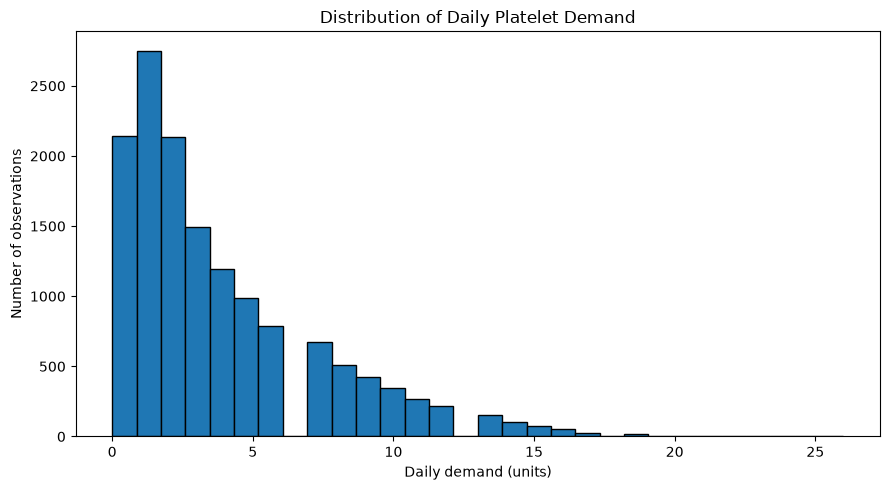

In [3]:
# Step 12.1: Visualize demand distribution

plt.figure(figsize=(9, 5))

plt.hist(
    df["daily_demand"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Daily Platelet Demand")
plt.xlabel("Daily demand (units)")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.show()

In [4]:
# Step 13.1: Sort operational data chronologically

df = df.sort_values(
    ["hospital_id", "blood_group", "date"]
).reset_index(drop=True)

print("Data sorted successfully.")
print("Rows:", len(df))

display(
    df[
        ["hospital_id", "blood_group", "date", "daily_demand"]
    ].head(10)
)

Data sorted successfully.
Rows: 14400


,hospital_id,blood_group,date,daily_demand
0,H001,A+,2026-01-01,8
1,H001,A+,2026-01-02,7
2,H001,A+,2026-01-03,4
3,H001,A+,2026-01-04,4
4,H001,A+,2026-01-05,4
5,H001,A+,2026-01-06,3
6,H001,A+,2026-01-07,6
7,H001,A+,2026-01-08,5
8,H001,A+,2026-01-09,4
9,H001,A+,2026-01-10,4


In [5]:
# Step 13.2: Create calendar features

df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

print("Calendar features created.")

display(
    df[
        [
            "date",
            "day_of_week",
            "month",
            "is_weekend",
            "daily_demand",
        ]
    ].head(10)
)

Calendar features created.


,date,day_of_week,month,is_weekend,daily_demand
0,2026-01-01,3,1,0,8
1,2026-01-02,4,1,0,7
2,2026-01-03,5,1,1,4
3,2026-01-04,6,1,1,4
4,2026-01-05,0,1,0,4
5,2026-01-06,1,1,0,3
6,2026-01-07,2,1,0,6
7,2026-01-08,3,1,0,5
8,2026-01-09,4,1,0,4
9,2026-01-10,5,1,1,4


In [6]:
# Step 13.3: Create lag and rolling-average features

group_columns = ["hospital_id", "blood_group"]

grouped_demand = df.groupby(
    group_columns,
    sort=False
)["daily_demand"]

# Demand on the previous day
df["lag_1"] = grouped_demand.shift(1)

# Demand seven days earlier
df["lag_7"] = grouped_demand.shift(7)

# Average demand over the preceding seven days
df["rolling_mean_7"] = grouped_demand.transform(
    lambda series: series.shift(1).rolling(
        window=7,
        min_periods=7
    ).mean()
)

# Average demand over the preceding fourteen days
df["rolling_mean_14"] = grouped_demand.transform(
    lambda series: series.shift(1).rolling(
        window=14,
        min_periods=14
    ).mean()
)

display(
    df[
        [
            "hospital_id",
            "blood_group",
            "date",
            "daily_demand",
            "lag_1",
            "lag_7",
            "rolling_mean_7",
            "rolling_mean_14",
        ]
    ].head(20)
)

,hospital_id,blood_group,date,daily_demand,lag_1,lag_7,rolling_mean_7,rolling_mean_14
0,H001,A+,2026-01-01,8,NaN,NaN,NaN,NaN
1,H001,A+,2026-01-02,7,8.0,NaN,NaN,NaN
2,H001,A+,2026-01-03,4,7.0,NaN,NaN,NaN
3,H001,A+,2026-01-04,4,4.0,NaN,NaN,NaN
4,H001,A+,2026-01-05,4,4.0,NaN,NaN,NaN
5,H001,A+,2026-01-06,3,4.0,NaN,NaN,NaN
6,H001,A+,2026-01-07,6,3.0,NaN,NaN,NaN
7,H001,A+,2026-01-08,5,6.0,8.0,5.142857,NaN
8,H001,A+,2026-01-09,4,5.0,7.0,4.714286,NaN
9,H001,A+,2026-01-10,4,4.0,4.0,4.285714,NaN


In [7]:
# Step 14.1: Remove rows without complete historical features

feature_columns = [
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_mean_7",
    "rolling_mean_14",
]

model_df = df.dropna(
    subset=feature_columns + ["daily_demand"]
).copy()

print("Original rows:", len(df))
print("Rows available for modelling:", len(model_df))
print("Rows removed due to insufficient history:", len(df) - len(model_df))

print(
    "Missing values in selected features:",
    model_df[feature_columns].isna().sum().sum()
)

display(model_df.head())

Original rows: 14400
Rows available for modelling: 13280
Rows removed due to insufficient history: 1120
Missing values in selected features: 0


,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,unmet_demand,emergency_event,is_synthetic,day_of_week,month,is_weekend,lag_1,lag_7,rolling_mean_7,rolling_mean_14
14,H001,2026-01-15,Platelets,A+,10,3,2,2,0,11,0,0,True,3,1,0,1.0,5.0,4.000000,4.571429
15,H001,2026-01-16,Platelets,A+,11,3,3,3,0,11,0,0,True,4,1,0,2.0,4.0,3.571429,4.142857
16,H001,2026-01-17,Platelets,A+,11,2,4,4,0,9,0,0,True,5,1,1,3.0,4.0,3.428571,3.857143
17,H001,2026-01-18,Platelets,A+,9,1,3,3,0,7,0,0,True,6,1,1,4.0,3.0,3.428571,3.857143
18,H001,2026-01-19,Platelets,A+,7,0,1,1,0,6,0,0,True,0,1,0,3.0,7.0,3.428571,3.785714


In [8]:
# Step 15.1: Encode categorical identifiers

model_df["hospital_code"] = (
    model_df["hospital_id"]
    .astype("category")
    .cat.codes
)

model_df["blood_group_code"] = (
    model_df["blood_group"]
    .astype("category")
    .cat.codes
)

print("Hospital codes:")
print(
    model_df[
        ["hospital_id", "hospital_code"]
    ].drop_duplicates().sort_values("hospital_code")
)

print("\nBlood-group codes:")
print(
    model_df[
        ["blood_group", "blood_group_code"]
    ].drop_duplicates().sort_values("blood_group_code")
)

Hospital codes:
      hospital_id  hospital_code
14           H001              0
1454         H002              1
2894         H003              2
4334         H004              3
5774         H005              4
7214         H006              5
8654         H007              6
10094        H008              7
11534        H009              8
12974        H010              9

Blood-group codes:
     blood_group  blood_group_code
14            A+                 0
194           A-                 1
374          AB+                 2
554          AB-                 3
734           B+                 4
914           B-                 5
1094          O+                 6
1274          O-                 7


In [9]:
# Step 16.1: Chronological train/test split

model_df = model_df.sort_values("date").reset_index(drop=True)

unique_dates = sorted(model_df["date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = model_df[
    model_df["date"] < split_date
].copy()

test_df = model_df[
    model_df["date"] >= split_date
].copy()

print("Training period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

assert train_df["date"].max() < test_df["date"].min()

print("\nChronological split verified.")

Training period:
2026-01-15 00:00:00 to 2026-05-26 00:00:00

Testing period:
2026-05-27 00:00:00 to 2026-06-29 00:00:00

Training rows: 10560
Testing rows: 2720

Chronological split verified.


In [10]:
# Step 17.1: Seven-day moving-average baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_train = train_df["daily_demand"]
y_test = test_df["daily_demand"]

baseline_predictions = test_df["rolling_mean_7"].to_numpy()

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

print("SEVEN-DAY BASELINE")
print("-" * 35)
print(f"MAE:  {baseline_mae:.3f}")
print(f"RMSE: {baseline_rmse:.3f}")

SEVEN-DAY BASELINE
-----------------------------------
MAE:  1.560
RMSE: 2.130


In [11]:
# Step 18.1: Train Random Forest

from sklearn.ensemble import RandomForestRegressor

feature_columns = [
    "hospital_code",
    "blood_group_code",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_mean_7",
    "rolling_mean_14",
]

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

model = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")
print("Training samples:", len(X_train))
print("Features:", len(feature_columns))

Random Forest training completed.
Training samples: 10560
Features: 9


In [12]:
# Step 18.2: Predict test-set demand

rf_predictions = model.predict(X_test)

# Demand cannot be negative
rf_predictions = np.maximum(0, rf_predictions)

print("Predictions generated:", len(rf_predictions))

display(
    pd.DataFrame({
        "date": test_df["date"].to_numpy(),
        "hospital_id": test_df["hospital_id"].to_numpy(),
        "blood_group": test_df["blood_group"].to_numpy(),
        "actual_demand": y_test.to_numpy(),
        "predicted_demand": rf_predictions,
        "baseline_prediction": baseline_predictions,
    }).head(10)
)

Predictions generated: 2720


,date,hospital_id,blood_group,actual_demand,predicted_demand,baseline_prediction
0,2026-05-27,H007,O+,3,5.936233,6.571429
1,2026-05-27,H010,A+,6,3.896837,5.428571
2,2026-05-27,H009,O-,5,2.275969,2.571429
3,2026-05-27,H009,AB-,0,0.861373,1.571429
4,2026-05-27,H005,B+,6,7.857865,5.428571
5,2026-05-27,H002,AB-,0,1.177985,1.142857
6,2026-05-27,H009,O+,8,11.903325,12.285714
7,2026-05-27,H009,A+,10,9.057299,10.285714
8,2026-05-27,H005,AB-,0,0.830913,0.857143
9,2026-05-27,H006,A-,4,2.407944,1.571429


In [13]:
# Step 19.1: Evaluate Random Forest

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

total_actual_demand = np.abs(y_test.to_numpy()).sum()

if total_actual_demand > 0:
    rf_wape = (
        np.abs(y_test.to_numpy() - rf_predictions).sum()
        / total_actual_demand
    ) * 100
else:
    rf_wape = np.nan

print("RANDOM FOREST RESULTS")
print("-" * 35)
print(f"MAE:  {rf_mae:.3f}")
print(f"RMSE: {rf_rmse:.3f}")
print(f"WAPE: {rf_wape:.2f}%")

print("\nBASELINE RESULTS")
print("-" * 35)
print(f"MAE:  {baseline_mae:.3f}")
print(f"RMSE: {baseline_rmse:.3f}")

print("\nMAE improvement over baseline:")

improvement = baseline_mae - rf_mae

print(f"{improvement:.3f} units")

RANDOM FOREST RESULTS
-----------------------------------
MAE:  1.556
RMSE: 2.096
WAPE: 42.50%

BASELINE RESULTS
-----------------------------------
MAE:  1.560
RMSE: 2.130

MAE improvement over baseline:
0.005 units


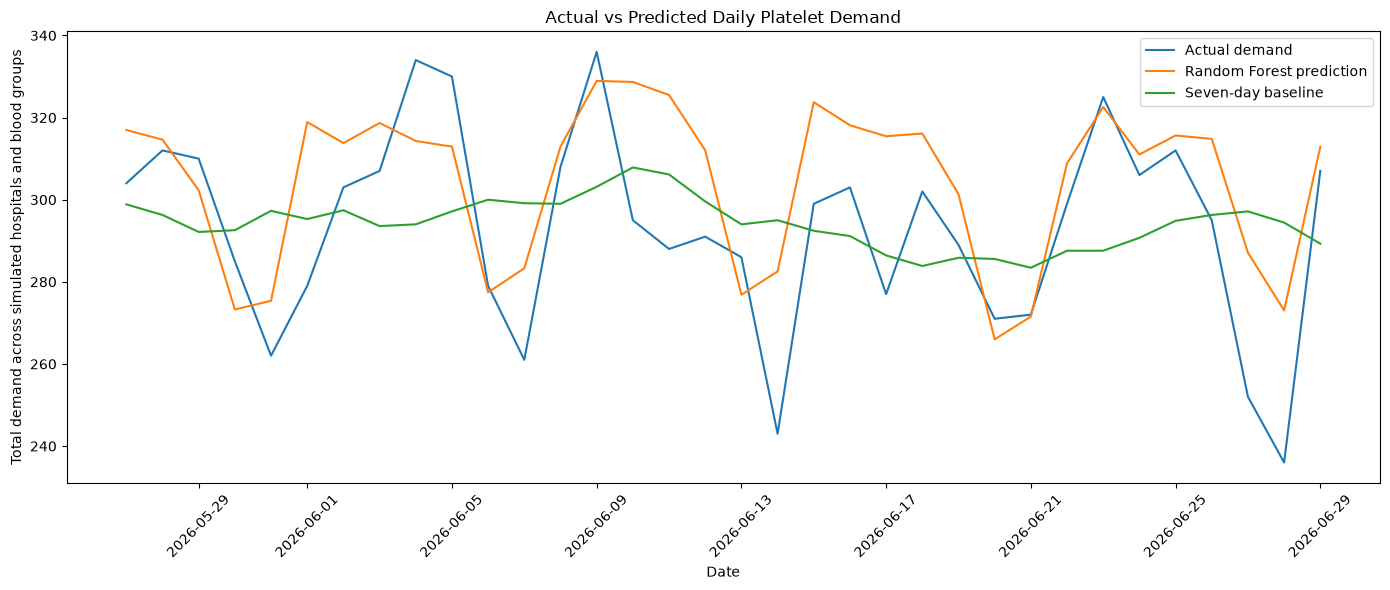

In [14]:
# Step 20.1: Actual versus predicted demand

plot_df = pd.DataFrame({
    "date": test_df["date"].to_numpy(),
    "actual": y_test.to_numpy(),
    "random_forest": rf_predictions,
    "baseline": baseline_predictions,
})

# Aggregate across hospitals and blood groups by date
daily_plot = (
    plot_df.groupby("date", as_index=False)[
        ["actual", "random_forest", "baseline"]
    ]
    .sum()
    .sort_values("date")
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_plot["date"],
    daily_plot["actual"],
    label="Actual demand"
)

plt.plot(
    daily_plot["date"],
    daily_plot["random_forest"],
    label="Random Forest prediction"
)

plt.plot(
    daily_plot["date"],
    daily_plot["baseline"],
    label="Seven-day baseline"
)

plt.title("Actual vs Predicted Daily Platelet Demand")
plt.xlabel("Date")
plt.ylabel("Total demand across simulated hospitals and blood groups")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Step 21.1: Save model evaluation metrics

import json

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metrics = {
    "data_source": "synthetic",
    "forecast_horizon_days": 1,
    "test_start": str(pd.Timestamp(test_df["date"].min()).date()),
    "test_end": str(pd.Timestamp(test_df["date"].max()).date()),
    "training_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "baseline_mae": float(baseline_mae),
    "baseline_rmse": float(baseline_rmse),
    "random_forest_mae": float(rf_mae),
    "random_forest_rmse": float(rf_rmse),
    "random_forest_wape_percent": float(rf_wape),
    "mae_improvement_over_baseline": float(improvement),
}

metrics_path = OUTPUT_DIR / "notebook_forecast_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Metrics saved to:", metrics_path)

Metrics saved to: b:\capstone-project\outputs\notebook_forecast_metrics.json


In [16]:
# Step 21.2: Save test-set predictions

predictions_df = pd.DataFrame({
    "date": test_df["date"].to_numpy(),
    "hospital_id": test_df["hospital_id"].to_numpy(),
    "blood_group": test_df["blood_group"].to_numpy(),
    "actual_demand": y_test.to_numpy(),
    "random_forest_prediction": rf_predictions,
    "seven_day_baseline": baseline_predictions,
})

predictions_path = OUTPUT_DIR / "notebook_forecast_test_predictions.csv"

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("Predictions saved to:", predictions_path)
print("Rows saved:", len(predictions_df))

Predictions saved to: b:\capstone-project\outputs\notebook_forecast_test_predictions.csv
Rows saved: 2720


In [17]:
# Step 22.1: Review saved model evaluation results

import json
from pathlib import Path
from IPython.display import display

metrics_path = (
    PROJECT_ROOT
    / "outputs"
    / "notebook_forecast_metrics.json"
)

with open(metrics_path, "r", encoding="utf-8") as file:
    metrics = json.load(file)

display(
    pd.DataFrame(
        list(metrics.items()),
        columns=["Metric", "Value"]
    )
)

,Metric,Value
0,data_source,synthetic
1,forecast_horizon_days,1
2,test_start,2026-05-27
3,test_end,2026-06-29
4,training_rows,10560
5,test_rows,2720
6,baseline_mae,1.560452
7,baseline_rmse,2.130167
8,random_forest_mae,1.55589
9,random_forest_rmse,2.095613


In [18]:
# Step 22.2: Interpret the baseline comparison

baseline_mae = metrics["baseline_mae"]
rf_mae = metrics["random_forest_mae"]

if rf_mae < baseline_mae:
    print("Random Forest performed better than the baseline on MAE.")
elif rf_mae > baseline_mae:
    print("The seven-day baseline performed better than Random Forest on MAE.")
else:
    print("Both methods had the same MAE.")

if baseline_mae > 0:
    improvement_percent = (
        (baseline_mae - rf_mae) / baseline_mae
    ) * 100

    print(f"MAE improvement: {improvement_percent:.2f}%")
else:
    print("Percentage improvement cannot be calculated because baseline MAE is zero.")

print("\nImportant limitation:")
print(
    "These results evaluate the model on synthetic data. "
    "They do not establish accuracy on real hospital demand."
)

Random Forest performed better than the baseline on MAE.
MAE improvement: 0.29%

Important limitation:
These results evaluate the model on synthetic data. They do not establish accuracy on real hospital demand.


In [19]:
# Step 23.1: Load saved test predictions

predictions_path = (
    PROJECT_ROOT
    / "outputs"
    / "notebook_forecast_test_predictions.csv"
)

predictions_df = pd.read_csv(
    predictions_path,
    parse_dates=["date"]
)

print("Prediction records:", len(predictions_df))

display(predictions_df.head())

Prediction records: 2720


,date,hospital_id,blood_group,actual_demand,random_forest_prediction,seven_day_baseline
0,2026-05-27,H007,O+,3,5.936233,6.571429
1,2026-05-27,H010,A+,6,3.896837,5.428571
2,2026-05-27,H009,O-,5,2.275969,2.571429
3,2026-05-27,H009,AB-,0,0.861373,1.571429
4,2026-05-27,H005,B+,6,7.857865,5.428571


In [20]:
# Step 23.2: Calculate absolute and signed errors

predictions_df["rf_error"] = (
    predictions_df["actual_demand"]
    - predictions_df["random_forest_prediction"]
)

predictions_df["rf_absolute_error"] = (
    predictions_df["rf_error"].abs()
)

predictions_df["baseline_error"] = (
    predictions_df["actual_demand"]
    - predictions_df["seven_day_baseline"]
)

predictions_df["baseline_absolute_error"] = (
    predictions_df["baseline_error"].abs()
)

display(
    predictions_df[
        [
            "date",
            "hospital_id",
            "blood_group",
            "actual_demand",
            "random_forest_prediction",
            "rf_absolute_error",
            "seven_day_baseline",
            "baseline_absolute_error",
        ]
    ].head(15)
)

,date,hospital_id,blood_group,actual_demand,random_forest_prediction,rf_absolute_error,seven_day_baseline,baseline_absolute_error
0,2026-05-27,H007,O+,3,5.936233,2.936233,6.571429,3.571429
1,2026-05-27,H010,A+,6,3.896837,2.103163,5.428571,0.571429
2,2026-05-27,H009,O-,5,2.275969,2.724031,2.571429,2.428571
3,2026-05-27,H009,AB-,0,0.861373,0.861373,1.571429,1.571429
4,2026-05-27,H005,B+,6,7.857865,1.857865,5.428571,0.571429
5,2026-05-27,H002,AB-,0,1.177985,1.177985,1.142857,1.142857
6,2026-05-27,H009,O+,8,11.903325,3.903325,12.285714,4.285714
7,2026-05-27,H009,A+,10,9.057299,0.942701,10.285714,0.285714
8,2026-05-27,H005,AB-,0,0.830913,0.830913,0.857143,0.857143
9,2026-05-27,H006,A-,4,2.407944,1.592056,1.571429,2.428571


In [21]:
# Step 23.3: Evaluate errors by hospital

hospital_errors = (
    predictions_df.groupby("hospital_id")
    .agg(
        actual_mean=("actual_demand", "mean"),
        predicted_mean=("random_forest_prediction", "mean"),
        MAE=("rf_absolute_error", "mean"),
        mean_signed_error=("rf_error", "mean"),
        observations=("actual_demand", "size"),
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(hospital_errors)

,hospital_id,actual_mean,predicted_mean,MAE,mean_signed_error,observations
8,H009,5.143382,5.346200,1.857870,-0.202818,272
2,H003,5.136029,5.192895,1.819246,-0.056865,272
7,H008,3.665441,3.870008,1.673561,-0.204567,272
5,H006,5.330882,5.203475,1.669854,0.127408,272
4,H005,3.621324,3.592268,1.601964,0.029055,272
1,H002,3.724265,3.937130,1.544276,-0.212865,272
6,H007,2.558824,2.766794,1.379932,-0.207970,272
3,H004,2.555147,2.793873,1.354643,-0.238726,272
0,H001,2.386029,2.563485,1.330953,-0.177455,272
9,H010,2.488971,2.776060,1.326598,-0.287090,272


In [22]:
# Step 24.1: Save the trained model

import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "demand_forecaster.joblib"

model_bundle = {
    "model": model,
    "features": feature_columns,
    "target": "daily_demand",
    "forecast_horizon_days": 1,
    "data_source": "synthetic",
    "model_type": "RandomForestRegressor",
}

joblib.dump(model_bundle, model_path)

print("Model saved to:", model_path)
print("Model file exists:", model_path.exists())

Model saved to: b:\capstone-project\models\demand_forecaster.joblib
Model file exists: True


In [23]:
# Step 25.1: Demonstrate shortage-risk calculations

# Illustrative operational inputs only.
# Replace these with actual inventory data when available.

shortage_demo = pd.DataFrame({
    "hospital_id": ["H001", "H002", "H003", "H004"],
    "blood_group": ["O+", "A+", "B+", "O-"],
    "current_usable_inventory": [20, 12, 8, 5],
    "confirmed_incoming_units": [4, 5, 2, 0],
    "predicted_demand": [18, 22, 15, 9],
})

shortage_demo["projected_inventory"] = (
    shortage_demo["current_usable_inventory"]
    + shortage_demo["confirmed_incoming_units"]
    - shortage_demo["predicted_demand"]
)

shortage_demo["potential_shortage_units"] = (
    -shortage_demo["projected_inventory"]
).clip(lower=0)

shortage_demo["shortage_flag"] = (
    shortage_demo["projected_inventory"] < 0
)

display(shortage_demo)

,hospital_id,blood_group,current_usable_inventory,confirmed_incoming_units,predicted_demand,projected_inventory,potential_shortage_units,shortage_flag
0,H001,O+,20,4,18,6,0,False
1,H002,A+,12,5,22,-5,5,True
2,H003,B+,8,2,15,-5,5,True
3,H004,O-,5,0,9,-4,4,True


In [24]:
# Step 25.2: Summarize potential shortages

at_risk = shortage_demo[
    shortage_demo["shortage_flag"]
]

print("Hospital/group combinations assessed:", len(shortage_demo))
print("Potential shortage combinations:", len(at_risk))

print(
    "Total illustrative shortage units:",
    int(at_risk["potential_shortage_units"].sum())
)

display(at_risk)

Hospital/group combinations assessed: 4
Potential shortage combinations: 3
Total illustrative shortage units: 14


,hospital_id,blood_group,current_usable_inventory,confirmed_incoming_units,predicted_demand,projected_inventory,potential_shortage_units,shortage_flag
1,H002,A+,12,5,22,-5,5,True
2,H003,B+,8,2,15,-5,5,True
3,H004,O-,5,0,9,-4,4,True


In [25]:
# Step 26.1: Demonstrate batch-level expiry-risk logic

from datetime import timedelta

# Illustrative data, not actual blood-bank inventory.
batch_demo = pd.DataFrame({
    "batch_id": ["B001", "B002", "B003", "B004"],
    "hospital_id": ["H001", "H001", "H002", "H003"],
    "blood_group": ["O+", "A+", "B+", "O-"],
    "units_available": [8, 5, 10, 4],
    "expiry_date": [
        "2026-10-22",
        "2026-10-24",
        "2026-10-30",
        "2026-10-21",
    ],
})

batch_demo["expiry_date"] = pd.to_datetime(
    batch_demo["expiry_date"]
)

as_of_date = pd.Timestamp("2026-10-21")
risk_window_days = 3

batch_demo["days_to_expiry"] = (
    batch_demo["expiry_date"] - as_of_date
).dt.days

batch_demo["expiry_risk"] = np.select(
    [
        batch_demo["days_to_expiry"] < 0,
        batch_demo["days_to_expiry"] <= risk_window_days,
    ],
    [
        "Past expiry date — investigate immediately",
        "Approaching expiry",
    ],
    default="Outside demonstration risk window",
)

display(batch_demo)

,batch_id,hospital_id,blood_group,units_available,expiry_date,days_to_expiry,expiry_risk
0,B001,H001,O+,8,2026-10-22,1,Approaching expiry
1,B002,H001,A+,5,2026-10-24,3,Approaching expiry
2,B003,H002,B+,10,2026-10-30,9,Outside demonstration risk window
3,B004,H003,O-,4,2026-10-21,0,Approaching expiry


In [26]:
# Step 27.2: Export a backend-compatible forecast sample

backend_forecasts = predictions_df[
    [
        "hospital_id",
        "blood_group",
        "date",
        "random_forest_prediction",
    ]
].rename(
    columns={
        "date": "forecast_date",
        "random_forest_prediction": "predicted_demand",
    }
).copy()

backend_forecasts["forecast_date"] = (
    backend_forecasts["forecast_date"].dt.strftime("%Y-%m-%d")
)

backend_forecasts["data_source"] = "synthetic"
backend_forecasts["forecast_horizon_days"] = 1

backend_output_path = (
    PROJECT_ROOT
    / "outputs"
    / "backend_forecast_sample.csv"
)

backend_forecasts.to_csv(
    backend_output_path,
    index=False
)

print("Backend sample saved to:", backend_output_path)
display(backend_forecasts.head())

Backend sample saved to: b:\capstone-project\outputs\backend_forecast_sample.csv


,hospital_id,blood_group,forecast_date,predicted_demand,data_source,forecast_horizon_days
0,H007,O+,2026-05-27,5.936233,synthetic,1
1,H010,A+,2026-05-27,3.896837,synthetic,1
2,H009,O-,2026-05-27,2.275969,synthetic,1
3,H009,AB-,2026-05-27,0.861373,synthetic,1
4,H005,B+,2026-05-27,7.857865,synthetic,1


In [27]:
# Step 28.1: Verify ML/Data pipeline outputs

from pathlib import Path
import pandas as pd
import json

required_files = {
    "Operational dataset": PROJECT_ROOT / "data" / "synthetic" / "platelet_inventory_demand.csv",
    "Trained model": PROJECT_ROOT / "models" / "demand_forecaster.joblib",
    "Evaluation metrics": PROJECT_ROOT / "outputs" / "notebook_forecast_metrics.json",
    "Test predictions": PROJECT_ROOT / "outputs" / "notebook_forecast_test_predictions.csv",
    "Backend forecast sample": PROJECT_ROOT / "outputs" / "backend_forecast_sample.csv",
}

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  Path: {path}")

Operational dataset: FOUND
  Path: b:\capstone-project\data\synthetic\platelet_inventory_demand.csv
Trained model: FOUND
  Path: b:\capstone-project\models\demand_forecaster.joblib
Evaluation metrics: FOUND
  Path: b:\capstone-project\outputs\notebook_forecast_metrics.json
Test predictions: FOUND
  Path: b:\capstone-project\outputs\notebook_forecast_test_predictions.csv
Backend forecast sample: FOUND
  Path: b:\capstone-project\outputs\backend_forecast_sample.csv


In [28]:
# Step 28.2: Check saved evaluation metrics

metrics_path = PROJECT_ROOT / "outputs" / "notebook_forecast_metrics.json"

with open(metrics_path, "r", encoding="utf-8") as file:
    metrics = json.load(file)

print("Data source:", metrics["data_source"])
print("Training rows:", metrics["training_rows"])
print("Testing rows:", metrics["test_rows"])
print("Baseline MAE:", round(metrics["baseline_mae"], 4))
print("Random Forest MAE:", round(metrics["random_forest_mae"], 4))
print("Random Forest RMSE:", round(metrics["random_forest_rmse"], 4))
print("Random Forest WAPE:", round(metrics["random_forest_wape_percent"], 2), "%")
print("MAE improvement:", round(metrics["mae_improvement_over_baseline"], 4))

Data source: synthetic
Training rows: 10560
Testing rows: 2720
Baseline MAE: 1.5605
Random Forest MAE: 1.5559
Random Forest RMSE: 2.0956
Random Forest WAPE: 42.5 %
MAE improvement: 0.0046


In [29]:
# Step 29.1: Compare model and baseline performance

comparison = pd.DataFrame({
    "Model": ["Seven-day baseline", "Random Forest"],
    "MAE": [
        metrics["baseline_mae"],
        metrics["random_forest_mae"],
    ],
    "RMSE": [
        metrics["baseline_rmse"],
        metrics["random_forest_rmse"],
    ],
})

display(comparison)

if metrics["random_forest_mae"] < metrics["baseline_mae"]:
    print("Random Forest has lower MAE than the baseline.")
else:
    print("The baseline matches or outperforms Random Forest on MAE.")

,Model,MAE,RMSE
0,Seven-day baseline,1.560452,2.130167
1,Random Forest,1.555890,2.095613


Random Forest has lower MAE than the baseline.


In [30]:
# Step 29.2: Inspect forecast errors

predictions_path = (
    PROJECT_ROOT
    / "outputs"
    / "notebook_forecast_test_predictions.csv"
)

predictions_df = pd.read_csv(predictions_path)

predictions_df["signed_error"] = (
    predictions_df["actual_demand"]
    - predictions_df["random_forest_prediction"]
)

predictions_df["absolute_error"] = (
    predictions_df["signed_error"].abs()
)

print(
    "Mean signed error:",
    round(predictions_df["signed_error"].mean(), 3)
)

print(
    "Mean absolute error:",
    round(predictions_df["absolute_error"].mean(), 3)
)

print(
    "Underprediction records:",
    (predictions_df["signed_error"] > 0).sum()
)

print(
    "Overprediction records:",
    (predictions_df["signed_error"] < 0).sum()
)

Mean signed error: -0.143
Mean absolute error: 1.556
Underprediction records: 1133
Overprediction records: 1587


Automate data-quality checks

In [31]:
# Step 31.1: Reusable operational dataset validation

def validate_operational_data(data):
    required_columns = [
        "hospital_id",
        "date",
        "blood_group",
        "opening_inventory",
        "incoming_units",
        "daily_demand",
        "units_used",
        "units_expired",
        "closing_inventory",
        "unmet_demand",
        "is_synthetic",
    ]

    missing_columns = [
        column for column in required_columns
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    if data[required_columns].isna().any().any():
        raise ValueError(
            "Required operational fields contain missing values."
        )

    numeric_columns = [
        "opening_inventory",
        "incoming_units",
        "daily_demand",
        "units_used",
        "units_expired",
        "closing_inventory",
        "unmet_demand",
    ]

    if (data[numeric_columns] < 0).any().any():
        raise ValueError(
            "Negative operational quantities detected."
        )

    expected_closing = (
        data["opening_inventory"]
        + data["incoming_units"]
        - data["units_used"]
        - data["units_expired"]
    )

    if not (
        expected_closing == data["closing_inventory"]
    ).all():
        raise ValueError(
            "Inventory accounting validation failed."
        )

    if (data["units_used"] > data["daily_demand"]).any():
        raise ValueError(
            "Units used exceed recorded demand."
        )

    if not (
        data["unmet_demand"]
        == data["daily_demand"] - data["units_used"]
    ).all():
        raise ValueError(
            "Unmet-demand validation failed."
        )

    duplicate_count = data.duplicated(
        subset=["hospital_id", "date", "blood_group"]
    ).sum()

    if duplicate_count:
        raise ValueError(
            f"Found {duplicate_count} duplicate time-series keys."
        )

    return {
        "status": "passed",
        "rows": len(data),
        "hospitals": data["hospital_id"].nunique(),
        "blood_groups": data["blood_group"].nunique(),
        "all_synthetic": bool(
            data["is_synthetic"].astype(bool).all()
        ),
    }

In [32]:
validation_report = validate_operational_data(df)

display(
    pd.DataFrame(
        list(validation_report.items()),
        columns=["Check", "Result"]
    )
)

,Check,Result
0,status,passed
1,rows,14400
2,hospitals,10
3,blood_groups,8
4,all_synthetic,True


In [33]:
# Improvement 1: Analyze demand variability

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("DEMAND VARIABILITY ANALYSIS")
print("-" * 45)

print("Mean demand:", round(df["daily_demand"].mean(), 3))
print("Standard deviation:", round(df["daily_demand"].std(), 3))
print("Minimum demand:", df["daily_demand"].min())
print("Maximum demand:", df["daily_demand"].max())

print(
    "Zero-demand percentage:",
    round((df["daily_demand"] == 0).mean() * 100, 2),
    "%"
)

print(
    "Emergency-event percentage:",
    round(df["emergency_event"].mean() * 100, 2),
    "%"
)

display(
    df.groupby("emergency_event")["daily_demand"]
    .agg(["count", "mean", "std", "min", "max"])
)

DEMAND VARIABILITY ANALYSIS
---------------------------------------------
Mean demand: 3.778
Standard deviation: 3.653
Minimum demand: 0
Maximum demand: 26
Zero-demand percentage: 14.87 %
Emergency-event percentage: 2.52 %


,count,mean,std,min,max
emergency_event,,,,,
0,14037,3.683123,3.595960,0,25
1,363,7.460055,3.930393,2,26


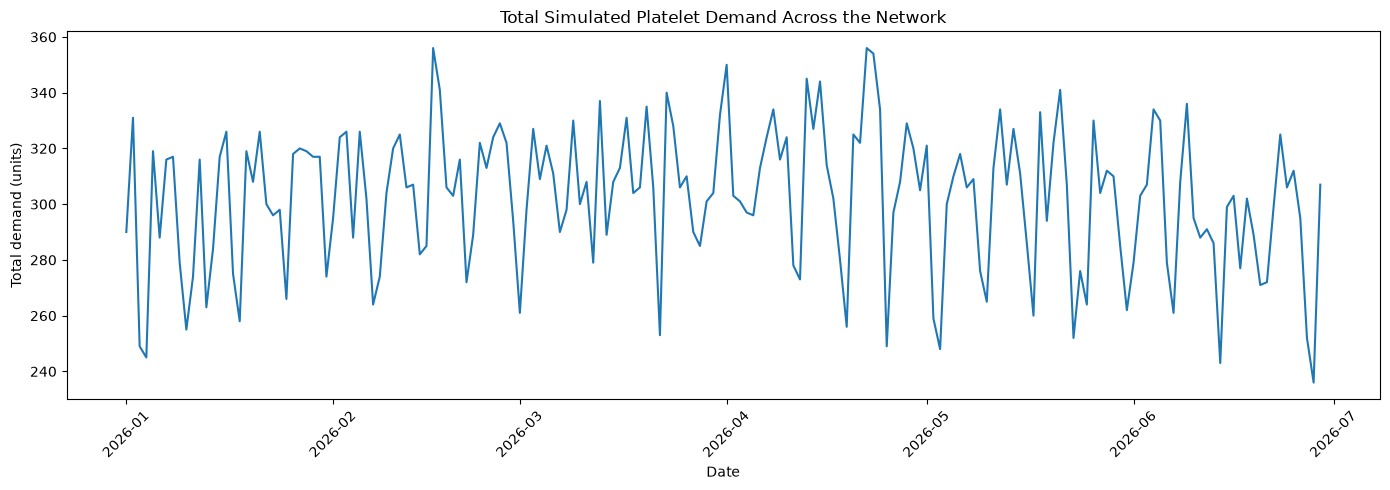

In [34]:
# Improvement 1.2: Aggregate demand by date

daily_demand = (
    df.groupby("date", as_index=False)["daily_demand"]
    .sum()
    .sort_values("date")
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand["date"],
    daily_demand["daily_demand"]
)

plt.title("Total Simulated Platelet Demand Across the Network")
plt.xlabel("Date")
plt.ylabel("Total demand (units)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
# Improvement 2: Import candidate forecasting models

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("Alternative forecasting models imported.")

Alternative forecasting models imported.


In [36]:
# Improvement 2.1: Compare forecasting models

import numpy as np
import pandas as pd

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

comparison_results = []

# Include the existing baseline
comparison_results.append({
    "Model": "Seven-day baseline",
    "MAE": mean_absolute_error(
        y_test,
        baseline_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_test,
            baseline_predictions
        )
    )
})

trained_models = {}

for name, candidate in models.items():

    print(f"Training {name}...")

    candidate.fit(X_train, y_train)

    predictions = np.maximum(
        0,
        candidate.predict(X_test)
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    comparison_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = candidate

comparison_results_df = (
    pd.DataFrame(comparison_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(comparison_results_df)

Training Random Forest...
Training Extra Trees...
Training HistGradientBoosting...


,Model,MAE,RMSE
0,HistGradientBoosting,1.513668,2.044260
1,Extra Trees,1.548240,2.091282
2,Random Forest,1.548661,2.084405
3,Seven-day baseline,1.560452,2.130167


In [37]:
# Improvement 3: Evaluate emergency-event performance

test_analysis = test_df[
    ["date", "hospital_id", "blood_group",
     "daily_demand", "emergency_event"]
].copy()

test_analysis["prediction"] = np.maximum(
    0,
    trained_models["Random Forest"].predict(
        test_df[feature_columns]
    )
)

test_analysis["absolute_error"] = (
    test_analysis["daily_demand"]
    - test_analysis["prediction"]
).abs()

emergency_results = (
    test_analysis.groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        mean_actual_demand=("daily_demand", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

display(emergency_results)

,emergency_event,records,mean_actual_demand,MAE
0,0,2660,3.571053,1.506766
1,1,60,7.650000,3.406022


In [38]:
# Improvement 1: Add additional historical demand features

df = df.sort_values(
    ["hospital_id", "blood_group", "date"]
).copy()

group_columns = ["hospital_id", "blood_group"]

grouped_demand = df.groupby(
    group_columns,
    sort=False
)["daily_demand"]

# Additional historical lags
for lag in [2, 3, 14]:
    df[f"lag_{lag}"] = grouped_demand.shift(lag)

# Rolling statistics use past observations only
df["rolling_std_7"] = grouped_demand.transform(
    lambda s: s.shift(1).rolling(
        window=7,
        min_periods=7
    ).std()
)

df["rolling_max_7"] = grouped_demand.transform(
    lambda s: s.shift(1).rolling(
        window=7,
        min_periods=7
    ).max()
)

df["rolling_min_7"] = grouped_demand.transform(
    lambda s: s.shift(1).rolling(
        window=7,
        min_periods=7
    ).min()
)

print("Additional historical features created.")

display(
    df[
        [
            "hospital_id",
            "blood_group",
            "date",
            "daily_demand",
            "lag_1",
            "lag_2",
            "lag_3",
            "lag_7",
            "lag_14",
            "rolling_std_7",
            "rolling_max_7",
            "rolling_min_7",
        ]
    ].head(20)
)

Additional historical features created.


,hospital_id,blood_group,date,daily_demand,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_std_7,rolling_max_7,rolling_min_7
0,H001,A+,2026-01-01,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,H001,A+,2026-01-02,7,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,H001,A+,2026-01-03,4,7.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN
3,H001,A+,2026-01-04,4,4.0,7.0,8.0,NaN,NaN,NaN,NaN,NaN
4,H001,A+,2026-01-05,4,4.0,4.0,7.0,NaN,NaN,NaN,NaN,NaN
5,H001,A+,2026-01-06,3,4.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN
6,H001,A+,2026-01-07,6,3.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN
7,H001,A+,2026-01-08,5,6.0,3.0,4.0,8.0,NaN,1.864454,8.0,3.0
8,H001,A+,2026-01-09,4,5.0,6.0,3.0,7.0,NaN,1.380131,7.0,3.0
9,H001,A+,2026-01-10,4,4.0,5.0,6.0,4.0,NaN,0.951190,6.0,3.0


In [39]:
# Step 1: Check whether the encoded columns exist

print("Hospital code exists:", "hospital_code" in df.columns)
print("Blood group code exists:", "blood_group_code" in df.columns)

print("\nCurrent columns:")
print(df.columns.tolist())

Hospital code exists: False
Blood group code exists: False

Current columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7']


In [40]:
# Step 2: Recreate categorical codes

df["hospital_code"] = (
    df["hospital_id"]
    .astype("category")
    .cat.codes
)

df["blood_group_code"] = (
    df["blood_group"]
    .astype("category")
    .cat.codes
)

print("Categorical encoding completed.")

print("\nHospital mapping:")
display(
    df[["hospital_id", "hospital_code"]]
    .drop_duplicates()
    .sort_values("hospital_code")
)

print("\nBlood group mapping:")
display(
    df[["blood_group", "blood_group_code"]]
    .drop_duplicates()
    .sort_values("blood_group_code")
)

Categorical encoding completed.

Hospital mapping:


,hospital_id,hospital_code
0,H001,0
1440,H002,1
2880,H003,2
4320,H004,3
5760,H005,4
7200,H006,5
8640,H007,6
10080,H008,7
11520,H009,8
12960,H010,9



Blood group mapping:


,blood_group,blood_group_code
0,A+,0
180,A-,1
360,AB+,2
540,AB-,3
720,B+,4
900,B-,5
1080,O+,6
1260,O-,7


In [41]:
# Step 3: Verify the required features

required_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

missing_features = [
    col for col in required_features
    if col not in df.columns
]

print("Missing features:", missing_features)

Missing features: []


In [42]:
# Step 4: Prepare the enhanced modelling dataset

enhanced_feature_columns = [
    "hospital_code",
    "blood_group_code",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

enhanced_df = df.dropna(
    subset=enhanced_feature_columns + ["daily_demand"]
).copy()

enhanced_df = enhanced_df.sort_values(
    "date"
).reset_index(drop=True)

print("Original dataset rows:", len(df))
print("Enhanced modelling rows:", len(enhanced_df))

print(
    "Missing feature values:",
    enhanced_df[enhanced_feature_columns].isna().sum().sum()
)

display(enhanced_df.head())

Original dataset rows: 14400
Enhanced modelling rows: 13280
Missing feature values: 0


,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,...,rolling_mean_7,rolling_mean_14,lag_2,lag_3,lag_14,rolling_std_7,rolling_max_7,rolling_min_7,hospital_code,blood_group_code
0,H001,2026-01-15,Platelets,A+,10,3,2,2,0,11,...,4.000000,4.571429,4.0,7.0,8.0,1.825742,7.0,1.0,0,0
1,H010,2026-01-15,Platelets,O+,3,10,3,3,0,10,...,5.000000,5.857143,6.0,3.0,4.0,1.414214,7.0,3.0,9,6
2,H008,2026-01-15,Platelets,O+,9,3,11,11,0,1,...,7.857143,7.500000,9.0,9.0,4.0,2.035401,10.0,5.0,7,6
3,H003,2026-01-15,Platelets,B+,9,3,12,12,0,0,...,8.571429,8.214286,10.0,11.0,9.0,3.101459,12.0,3.0,2,4
4,H006,2026-01-15,Platelets,O+,0,21,8,8,0,13,...,11.857143,12.357143,9.0,12.0,13.0,6.094494,25.0,6.0,5,6


In [43]:
# Improvement 2: Prepare the expanded feature set

enhanced_feature_columns = [
    "hospital_code",
    "blood_group_code",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

enhanced_df = df.dropna(
    subset=enhanced_feature_columns + ["daily_demand"]
).copy()

enhanced_df = enhanced_df.sort_values(
    "date"
).reset_index(drop=True)

print("Original dataset rows:", len(df))
print("Enhanced modelling rows:", len(enhanced_df))
print(
    "Rows removed due to insufficient history:",
    len(df) - len(enhanced_df)
)

print(
    "Missing values in enhanced features:",
    enhanced_df[enhanced_feature_columns].isna().sum().sum()
)

Original dataset rows: 14400
Enhanced modelling rows: 13280
Rows removed due to insufficient history: 1120
Missing values in enhanced features: 0


In [44]:
# Improvement 3: Chronological split for enhanced experiment

unique_dates = np.sort(
    enhanced_df["date"].dropna().unique()
)

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

enhanced_train_df = enhanced_df[
    enhanced_df["date"] < split_date
].copy()

enhanced_test_df = enhanced_df[
    enhanced_df["date"] >= split_date
].copy()

print("Training dates:")
print(
    enhanced_train_df["date"].min(),
    "to",
    enhanced_train_df["date"].max()
)

print("\nTesting dates:")
print(
    enhanced_test_df["date"].min(),
    "to",
    enhanced_test_df["date"].max()
)

print("\nTraining records:", len(enhanced_train_df))
print("Testing records:", len(enhanced_test_df))

assert (
    enhanced_train_df["date"].max()
    < enhanced_test_df["date"].min()
)

print("\nChronological split verified.")

Training dates:
2026-01-15 00:00:00 to 2026-05-26 00:00:00

Testing dates:
2026-05-27 00:00:00 to 2026-06-29 00:00:00

Training records: 10560
Testing records: 2720

Chronological split verified.


In [45]:
# Improvement 4: Train HistGradientBoosting with enhanced features

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_train_enhanced = enhanced_train_df[
    enhanced_feature_columns
]

X_test_enhanced = enhanced_test_df[
    enhanced_feature_columns
]

y_train_enhanced = enhanced_train_df["daily_demand"]
y_test_enhanced = enhanced_test_df["daily_demand"]

enhanced_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

enhanced_model.fit(
    X_train_enhanced,
    y_train_enhanced
)

enhanced_predictions = np.maximum(
    0,
    enhanced_model.predict(X_test_enhanced)
)

print("Enhanced HistGradientBoosting model trained.")
print("Predictions generated:", len(enhanced_predictions))

Enhanced HistGradientBoosting model trained.
Predictions generated: 2720


In [46]:
# Improvement 5.1: Calculate enhanced model evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Generate predictions if they have not been created
enhanced_predictions = np.maximum(
    0,
    enhanced_model.predict(X_test_enhanced)
)

# Calculate MAE
enhanced_mae = mean_absolute_error(
    y_test_enhanced,
    enhanced_predictions
)

# Calculate RMSE
enhanced_rmse = np.sqrt(
    mean_squared_error(
        y_test_enhanced,
        enhanced_predictions
    )
)

# Calculate WAPE
total_actual = np.abs(
    y_test_enhanced.to_numpy()
).sum()

enhanced_wape = (
    np.abs(
        y_test_enhanced.to_numpy()
        - enhanced_predictions
    ).sum()
    / total_actual
    * 100
    if total_actual > 0
    else np.nan
)

print("ENHANCED HISTGRADIENTBOOSTING RESULTS")
print("-" * 45)
print(f"MAE:  {enhanced_mae:.4f}")
print(f"RMSE: {enhanced_rmse:.4f}")
print(f"WAPE: {enhanced_wape:.2f}%")

ENHANCED HISTGRADIENTBOOSTING RESULTS
---------------------------------------------
MAE:  1.5161
RMSE: 2.0489
WAPE: 41.41%


In [47]:
# Improvement 5.2: Fair comparison on identical test records

enhanced_baseline_predictions = (
    enhanced_test_df["rolling_mean_7"].to_numpy()
)

enhanced_baseline_mae = mean_absolute_error(
    y_test_enhanced,
    enhanced_baseline_predictions
)

enhanced_baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test_enhanced,
        enhanced_baseline_predictions
    )
)

enhanced_comparison = pd.DataFrame({
    "Model": [
        "Seven-day baseline",
        "Enhanced HistGradientBoosting",
    ],
    "MAE": [
        enhanced_baseline_mae,
        enhanced_mae,
    ],
    "RMSE": [
        enhanced_baseline_rmse,
        enhanced_rmse,
    ],
})

display(enhanced_comparison)

mae_improvement_pct = (
    (enhanced_baseline_mae - enhanced_mae)
    / enhanced_baseline_mae
    * 100
    if enhanced_baseline_mae > 0
    else np.nan
)

print(
    f"MAE improvement over baseline: "
    f"{mae_improvement_pct:.2f}%"
)

,Model,MAE,RMSE
0,Seven-day baseline,1.560452,2.130167
1,Enhanced HistGradientBoosting,1.516097,2.048881


MAE improvement over baseline: 2.84%


In [48]:
# Improvement 6: Evaluate enhanced model on emergency records

emergency_test = enhanced_test_df[
    ["date", "hospital_id", "blood_group",
     "daily_demand", "emergency_event"]
].copy()

emergency_test["prediction"] = enhanced_predictions

emergency_test["absolute_error"] = (
    emergency_test["daily_demand"]
    - emergency_test["prediction"]
).abs()

emergency_metrics = (
    emergency_test.groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        actual_mean=("daily_demand", "mean"),
        MAE=("absolute_error", "mean"),
        maximum_actual_demand=("daily_demand", "max"),
    )
    .reset_index()
)

display(emergency_metrics)

,emergency_event,records,actual_mean,MAE,maximum_actual_demand
0,0,2660,3.571053,1.473701,21
1,1,60,7.650000,3.395654,18


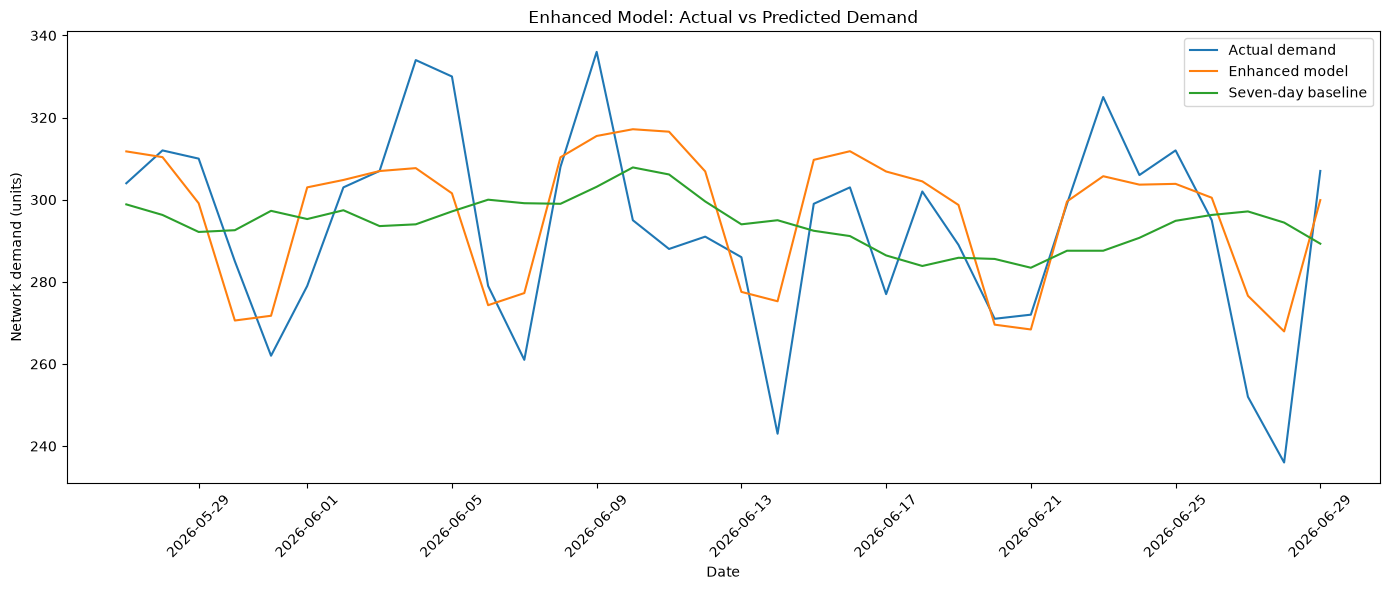

In [49]:
# Improvement 7: Plot actual versus enhanced predictions

enhanced_plot_df = pd.DataFrame({
    "date": enhanced_test_df["date"].to_numpy(),
    "actual": y_test_enhanced.to_numpy(),
    "prediction": enhanced_predictions,
    "baseline": enhanced_baseline_predictions,
})

daily_comparison = (
    enhanced_plot_df.groupby("date", as_index=False)[
        ["actual", "prediction", "baseline"]
    ]
    .sum()
    .sort_values("date")
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_comparison["date"],
    daily_comparison["actual"],
    label="Actual demand"
)

plt.plot(
    daily_comparison["date"],
    daily_comparison["prediction"],
    label="Enhanced model"
)

plt.plot(
    daily_comparison["date"],
    daily_comparison["baseline"],
    label="Seven-day baseline"
)

plt.title("Enhanced Model: Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Network demand (units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
# Step 1: Analyze enhanced-model prediction errors

enhanced_error_df = enhanced_test_df[
    [
        "date",
        "hospital_id",
        "blood_group",
        "daily_demand",
        "emergency_event",
    ]
].copy()

enhanced_error_df["predicted_demand"] = enhanced_predictions

enhanced_error_df["signed_error"] = (
    enhanced_error_df["daily_demand"]
    - enhanced_error_df["predicted_demand"]
)

enhanced_error_df["absolute_error"] = (
    enhanced_error_df["signed_error"].abs()
)

print("Enhanced-model error analysis")
print("-" * 40)

print(
    "Mean absolute error:",
    round(enhanced_error_df["absolute_error"].mean(), 4)
)

print(
    "Mean signed error:",
    round(enhanced_error_df["signed_error"].mean(), 4)
)

print(
    "Underprediction records:",
    (enhanced_error_df["signed_error"] > 0).sum()
)

print(
    "Overprediction records:",
    (enhanced_error_df["signed_error"] < 0).sum()
)

display(
    enhanced_error_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(15)
)

Enhanced-model error analysis
----------------------------------------
Mean absolute error: 1.5161
Mean signed error: -0.0469
Underprediction records: 1111
Overprediction records: 1609


,date,hospital_id,blood_group,daily_demand,emergency_event,predicted_demand,signed_error,absolute_error
11225,2026-06-04,H003,A+,21,0,9.499244,11.500756,11.500756
11428,2026-06-06,H008,O+,16,0,5.142974,10.857026,10.857026
13251,2026-06-29,H009,O+,21,0,11.103220,9.896780,9.896780
12736,2026-06-23,H003,O+,21,0,11.671231,9.328769,9.328769
11851,2026-06-12,H006,B+,18,1,9.120429,8.879571,8.879571
12738,2026-06-23,H009,O+,18,0,9.151056,8.848944,8.848944
11083,2026-06-02,H005,A+,14,0,5.389758,8.610242,8.610242
11245,2026-06-04,H003,O+,19,0,10.726596,8.273404,8.273404
11562,2026-06-08,H009,O+,4,0,12.094495,-8.094495,8.094495
10697,2026-05-28,H002,AB+,12,1,4.037011,7.962989,7.962989


In [51]:
# Step 2: Evaluate enhanced-model performance by emergency status

emergency_performance = (
    enhanced_error_df.groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        average_actual_demand=("daily_demand", "mean"),
        MAE=("absolute_error", "mean"),
        mean_signed_error=("signed_error", "mean"),
    )
    .reset_index()
)

display(emergency_performance)

,emergency_event,records,average_actual_demand,MAE,mean_signed_error
0,0,2660,3.571053,1.473701,-0.118506
1,1,60,7.650000,3.395654,3.125730


In [52]:
# Step 3: Compare enhanced model and baseline

enhanced_baseline_predictions = (
    enhanced_test_df["rolling_mean_7"].to_numpy()
)

baseline_mae_same_test = mean_absolute_error(
    y_test_enhanced,
    enhanced_baseline_predictions
)

baseline_rmse_same_test = np.sqrt(
    mean_squared_error(
        y_test_enhanced,
        enhanced_baseline_predictions
    )
)

enhanced_comparison_final = pd.DataFrame({
    "Model": [
        "Seven-day baseline",
        "Enhanced HistGradientBoosting",
    ],
    "MAE": [
        baseline_mae_same_test,
        enhanced_mae,
    ],
    "RMSE": [
        baseline_rmse_same_test,
        enhanced_rmse,
    ],
})

display(enhanced_comparison_final)

print(
    "MAE improvement over baseline:",
    round(
        (
            baseline_mae_same_test - enhanced_mae
        ) / baseline_mae_same_test * 100,
        2
    ),
    "%"
)

,Model,MAE,RMSE
0,Seven-day baseline,1.560452,2.130167
1,Enhanced HistGradientBoosting,1.516097,2.048881


MAE improvement over baseline: 2.84 %


Analyze demand by hospital

In [53]:
# Step 1: Analyze demand by hospital

hospital_demand_analysis = (
    df.groupby("hospital_id")["daily_demand"]
    .agg(
        mean_demand="mean",
        std_demand="std",
        minimum_demand="min",
        maximum_demand="max",
        observations="count",
    )
    .reset_index()
    .sort_values("mean_demand", ascending=False)
)

display(hospital_demand_analysis)

,hospital_id,mean_demand,std_demand,minimum_demand,maximum_demand,observations
5,H006,5.418056,4.543843,0,25,1440
2,H003,5.398611,4.630863,0,22,1440
8,H009,5.347222,4.534202,0,26,1440
1,H002,3.872222,3.498286,0,19,1440
7,H008,3.773611,3.416450,0,17,1440
4,H005,3.711111,3.317549,0,16,1440
9,H010,2.627083,2.416463,0,14,1440
3,H004,2.575694,2.377762,0,14,1440
6,H007,2.560417,2.362368,0,13,1440
0,H001,2.499306,2.278705,0,12,1440


In [54]:
# Step 2: Analyze demand by day of week

weekday_analysis = (
    df.groupby("day_of_week")["daily_demand"]
    .agg(
        mean_demand="mean",
        std_demand="std",
        observations="count",
    )
    .reset_index()
)

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}

weekday_analysis["weekday"] = (
    weekday_analysis["day_of_week"].map(weekday_names)
)

display(
    weekday_analysis[
        ["weekday", "mean_demand", "std_demand", "observations"]
    ]
)

,weekday,mean_demand,std_demand,observations
0,Monday,3.921154,3.689426,2080
1,Tuesday,3.967000,3.857636,2000
2,Wednesday,3.927500,3.829697,2000
3,Thursday,3.911058,3.740278,2080
4,Friday,3.890865,3.695884,2080
5,Saturday,3.453365,3.376024,2080
6,Sunday,3.390385,3.314594,2080


In [55]:
# Step 3: Correlation between historical and current demand

correlation_features = [
    "daily_demand",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
]

correlation_df = df[correlation_features].corr()

display(correlation_df)

,daily_demand,lag_1,lag_2,lag_3,lag_7,lag_14
daily_demand,1.000000,0.692721,0.687703,0.689319,0.694641,0.691624
lag_1,0.692721,1.000000,0.693074,0.688111,0.696845,0.691548
lag_2,0.687703,0.693074,1.000000,0.692983,0.690755,0.686870
lag_3,0.689319,0.688111,0.692983,1.000000,0.683172,0.687362
lag_7,0.694641,0.696845,0.690755,0.683172,1.000000,0.694468
lag_14,0.691624,0.691548,0.686870,0.687362,0.694468,1.000000


In [56]:
HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


Create a chronological training and validation split

In [57]:
# Step 1: Create chronological training and validation sets

import numpy as np
import pandas as pd

enhanced_df = enhanced_df.sort_values("date").copy()

unique_dates = np.sort(
    enhanced_df["date"].dropna().unique()
)

train_end = int(len(unique_dates) * 0.70)
validation_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
validation_dates = unique_dates[train_end:validation_end]
test_dates = unique_dates[validation_end:]

train_model_df = enhanced_df[
    enhanced_df["date"].isin(train_dates)
].copy()

validation_df = enhanced_df[
    enhanced_df["date"].isin(validation_dates)
].copy()

final_test_df = enhanced_df[
    enhanced_df["date"].isin(test_dates)
].copy()

print("Training records:", len(train_model_df))
print("Validation records:", len(validation_df))
print("Final test records:", len(final_test_df))

print("\nTraining period:")
print(train_model_df["date"].min(), "to", train_model_df["date"].max())

print("\nValidation period:")
print(validation_df["date"].min(), "to", validation_df["date"].max())

print("\nFinal test period:")
print(final_test_df["date"].min(), "to", final_test_df["date"].max())

assert train_model_df["date"].max() < validation_df["date"].min()
assert validation_df["date"].max() < final_test_df["date"].min()

print("\nChronological split verified.")

Training records: 9280
Validation records: 2000
Final test records: 2000

Training period:
2026-01-15 00:00:00 to 2026-05-10 00:00:00

Validation period:
2026-05-11 00:00:00 to 2026-06-04 00:00:00

Final test period:
2026-06-05 00:00:00 to 2026-06-29 00:00:00

Chronological split verified.


In [58]:
# Step 2: Train HistGradientBoosting on the training period

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_train = train_model_df[enhanced_feature_columns]
y_train = train_model_df["daily_demand"]

X_validation = validation_df[enhanced_feature_columns]
y_validation = validation_df["daily_demand"]

validation_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

validation_model.fit(X_train, y_train)

validation_predictions = np.maximum(
    0,
    validation_model.predict(X_validation)
)

print("Validation model trained successfully.")
print("Validation predictions:", len(validation_predictions))

Validation model trained successfully.
Validation predictions: 2000


In [59]:
# Step 3: Evaluate the validation model

validation_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

validation_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        validation_predictions
    )
)

validation_actual_total = y_validation.abs().sum()

validation_wape = (
    np.abs(
        y_validation.to_numpy()
        - validation_predictions
    ).sum()
    / validation_actual_total
    * 100
    if validation_actual_total > 0
    else np.nan
)

print("VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:  {validation_mae:.4f}")
print(f"RMSE: {validation_rmse:.4f}")
print(f"WAPE: {validation_wape:.2f}%")

VALIDATION RESULTS
----------------------------------------
MAE:  1.5685
RMSE: 2.0848
WAPE: 41.53%


In [60]:
# Step 4: Evaluate emergency and non-emergency demand

validation_analysis = validation_df[
    [
        "date",
        "hospital_id",
        "blood_group",
        "daily_demand",
        "emergency_event"
    ]
].copy()

validation_analysis["prediction"] = validation_predictions

validation_analysis["absolute_error"] = (
    validation_analysis["daily_demand"]
    - validation_analysis["prediction"]
).abs()

emergency_validation_results = (
    validation_analysis.groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        mean_actual_demand=("daily_demand", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

display(emergency_validation_results)

,emergency_event,records,mean_actual_demand,MAE
0,0,1961,3.713412,1.524847
1,1,39,6.948718,3.765826


Validation baseline comparison

In [61]:
# Step 1: Compare HistGradientBoosting against the baseline
# on the exact same validation records.

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Baseline: average demand over the preceding seven days.
validation_baseline_predictions = (
    validation_df["rolling_mean_7"].to_numpy()
)

# Model predictions already calculated in the validation experiment.
model_predictions = np.maximum(
    0,
    validation_predictions
)

y_validation_array = y_validation.to_numpy()

baseline_mae = mean_absolute_error(
    y_validation_array,
    validation_baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation_array,
        validation_baseline_predictions
    )
)

model_mae = mean_absolute_error(
    y_validation_array,
    model_predictions
)

model_rmse = np.sqrt(
    mean_squared_error(
        y_validation_array,
        model_predictions
    )
)

validation_comparison = pd.DataFrame({
    "Model": [
        "Seven-day baseline",
        "HistGradientBoosting"
    ],
    "MAE": [
        baseline_mae,
        model_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse
    ]
})

display(validation_comparison)

if baseline_mae > 0:
    improvement = (
        (baseline_mae - model_mae)
        / baseline_mae
        * 100
    )

    print(
        f"MAE improvement over baseline: {improvement:.2f}%"
    )

,Model,MAE,RMSE
0,Seven-day baseline,1.610071,2.142417
1,HistGradientBoosting,1.568546,2.084841


MAE improvement over baseline: 2.58%


In [62]:
# Step 2: Analyze weekday patterns by hospital

weekday_hospital_analysis = (
    df.groupby(
        ["hospital_id", "day_of_week"]
    )["daily_demand"]
    .mean()
    .reset_index(name="mean_demand")
)

weekday_pivot = weekday_hospital_analysis.pivot(
    index="hospital_id",
    columns="day_of_week",
    values="mean_demand"
)

weekday_pivot = weekday_pivot.rename(
    columns={
        0: "Monday",
        1: "Tuesday",
        2: "Wednesday",
        3: "Thursday",
        4: "Friday",
        5: "Saturday",
        6: "Sunday"
    }
)

display(weekday_pivot.round(2))

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hospital_id,,,,,,,
H001,2.62,2.59,2.70,2.50,2.48,2.28,2.33
H002,3.88,4.34,3.92,4.01,4.01,3.58,3.38
H003,5.38,5.90,5.54,5.53,5.64,4.93,4.90
H004,2.79,2.48,2.68,2.63,2.70,2.39,2.36
H005,3.75,4.04,4.08,3.87,3.88,3.28,3.12
H006,5.70,5.38,5.69,5.73,5.66,4.92,4.86
H007,2.69,2.82,2.72,2.61,2.49,2.28,2.33
H008,3.93,3.98,3.86,3.91,3.84,3.51,3.39
H009,5.50,5.52,5.50,5.59,5.46,5.00,4.87


In [63]:
# Step 3: Train a regularized linear regression model

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(alpha=10.0)
)

ridge_model.fit(
    X_train,
    y_train
)

ridge_predictions = np.maximum(
    0,
    ridge_model.predict(X_validation)
)

ridge_mae = mean_absolute_error(
    y_validation,
    ridge_predictions
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        ridge_predictions
    )
)

print("RIDGE REGRESSION VALIDATION RESULTS")
print("-" * 45)
print(f"MAE:  {ridge_mae:.4f}")
print(f"RMSE: {ridge_rmse:.4f}")

RIDGE REGRESSION VALIDATION RESULTS
---------------------------------------------
MAE:  1.5510
RMSE: 2.0705


In [64]:
# Step 4: Compare all models on the validation period

validation_models_comparison = pd.DataFrame({
    "Model": [
        "Seven-day baseline",
        "HistGradientBoosting",
        "Ridge regression"
    ],
    "MAE": [
        baseline_mae,
        model_mae,
        ridge_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse,
        ridge_rmse
    ]
}).sort_values(
    "MAE"
).reset_index(drop=True)

display(validation_models_comparison)

,Model,MAE,RMSE
0,Ridge regression,1.551024,2.070546
1,HistGradientBoosting,1.568546,2.084841
2,Seven-day baseline,1.610071,2.142417


In [65]:
# Step 1: Import XGBoost

from xgboost import XGBRegressor

print("XGBoost imported successfully.")

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
enhanced_feature_columns

['hospital_code',
 'blood_group_code',
 'day_of_week',
 'month',
 'is_weekend',
 'lag_1',
 'lag_2',
 'lag_3',
 'lag_7',
 'lag_14',
 'rolling_mean_7',
 'rolling_mean_14',
 'rolling_std_7',
 'rolling_max_7',
 'rolling_min_7']

In [ ]:
train_model_df
validation_df

,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,...,rolling_mean_7,rolling_mean_14,lag_2,lag_3,lag_14,rolling_std_7,rolling_max_7,rolling_min_7,hospital_code,blood_group_code
9322,H002,2026-05-11,Platelets,A+,7,7,9,9,0,5,...,8.714286,6.928571,5.0,6.0,2.0,3.147183,13.0,5.0,1,0
9332,H001,2026-05-11,Platelets,B-,3,1,2,2,0,2,...,1.428571,1.214286,1.0,2.0,2.0,0.534522,2.0,1.0,0,5
9333,H002,2026-05-11,Platelets,B+,9,2,7,7,0,4,...,6.571429,6.785714,5.0,12.0,7.0,3.258688,12.0,2.0,1,4
9337,H003,2026-05-11,Platelets,B+,6,7,7,7,0,6,...,7.428571,8.357143,7.0,12.0,12.0,2.299068,12.0,5.0,2,4
9335,H002,2026-05-11,Platelets,O-,7,0,1,1,0,6,...,1.571429,1.571429,0.0,2.0,1.0,1.812654,4.0,0.0,1,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11225,H003,2026-06-04,Platelets,A+,3,18,21,21,0,0,...,10.000000,9.714286,8.0,13.0,5.0,2.449490,13.0,6.0,2,0
11224,H008,2026-06-04,Platelets,AB-,13,0,1,1,0,12,...,0.428571,1.142857,1.0,0.0,2.0,0.786796,2.0,0.0,7,3
11223,H003,2026-06-04,Platelets,B+,12,2,11,11,0,3,...,6.714286,8.214286,4.0,7.0,14.0,1.889822,9.0,4.0,2,4
11222,H008,2026-06-04,Platelets,A+,1,16,11,11,0,6,...,6.714286,6.500000,11.0,8.0,8.0,2.563480,11.0,4.0,7,0


In [ ]:
# Step 2: Prepare XGBoost training and validation data

import numpy as np

X_train_xgb = train_model_df[
    enhanced_feature_columns
]

y_train_xgb = train_model_df[
    "daily_demand"
]

X_validation_xgb = validation_df[
    enhanced_feature_columns
]

y_validation_xgb = validation_df[
    "daily_demand"
]

print("Training rows:", len(X_train_xgb))
print("Validation rows:", len(X_validation_xgb))

print("Training features:", X_train_xgb.shape[1])
print("Validation features:", X_validation_xgb.shape[1])

Training rows: 9280
Validation rows: 2000
Training features: 15
Validation features: 15


In [ ]:
# Step 3: Train XGBoost

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=2.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(
    X_train_xgb,
    y_train_xgb,
    verbose=False
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
# Step 4: Evaluate XGBoost on validation data

from sklearn.metrics import mean_absolute_error, mean_squared_error

xgb_validation_predictions = np.maximum(
    0,
    xgb_model.predict(X_validation_xgb)
)

xgb_mae = mean_absolute_error(
    y_validation_xgb,
    xgb_validation_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation_xgb,
        xgb_validation_predictions
    )
)

actual_total = y_validation_xgb.abs().sum()

xgb_wape = (
    np.abs(
        y_validation_xgb.to_numpy()
        - xgb_validation_predictions
    ).sum()
    / actual_total
    * 100
    if actual_total > 0
    else np.nan
)

print("XGBOOST VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:  {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"WAPE: {xgb_wape:.2f}%")

XGBOOST VALIDATION RESULTS
----------------------------------------
MAE:  1.5625
RMSE: 2.0862
WAPE: 41.38%


In [ ]:
# Step 5: Compare models on the validation period

import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Seven-day baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse
    },
    {
        "Model": "HistGradientBoosting",
        "MAE": model_mae,
        "RMSE": model_rmse
    },
    {
        "Model": "Ridge Regression",
        "MAE": ridge_mae,
        "RMSE": ridge_rmse
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse
    }
])

model_comparison = (
    model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(model_comparison)

,Model,MAE,RMSE
0,Ridge Regression,1.551024,2.070546
1,XGBoost,1.562541,2.086240
2,HistGradientBoosting,1.566331,2.084173
3,Seven-day baseline,1.610071,2.142417


In [ ]:
# Step 6: Evaluate XGBoost on emergency and non-emergency records

xgb_error_df = validation_df[
    [
        "date",
        "hospital_id",
        "blood_group",
        "daily_demand",
        "emergency_event"
    ]
].copy()

xgb_error_df["prediction"] = xgb_validation_predictions

xgb_error_df["absolute_error"] = (
    xgb_error_df["daily_demand"]
    - xgb_error_df["prediction"]
).abs()

xgb_emergency_results = (
    xgb_error_df.groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        mean_actual_demand=("daily_demand", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

display(xgb_emergency_results)

,emergency_event,records,mean_actual_demand,MAE
0,0,1961,3.713412,1.518969
1,1,39,6.948718,3.753400


In [ ]:
# Step 1: Prepare categorical and numerical features

categorical_features = [
    "hospital_id",
    "blood_group",
]

numeric_features = [
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

model_features = categorical_features + numeric_features

print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)

print("\nTraining rows:", len(train_model_df))
print("Validation rows:", len(validation_df))

Categorical features: ['hospital_id', 'blood_group']
Numerical features: ['day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7']

Training rows: 9280
Validation rows: 2000


In [ ]:
# Step 2: Ridge Regression with proper categorical encoding

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    ),
])

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
])

preprocessor = ColumnTransformer([
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
])

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

X_train_categorical = train_model_df[model_features]
y_train_categorical = train_model_df["daily_demand"]

X_validation_categorical = validation_df[model_features]
y_validation_categorical = validation_df["daily_demand"]

ridge_pipeline.fit(
    X_train_categorical,
    y_train_categorical
)

ridge_encoded_predictions = np.maximum(
    0,
    ridge_pipeline.predict(X_validation_categorical)
)

print("Categorically encoded Ridge model trained.")

Categorically encoded Ridge model trained.


In [ ]:
# Step 3: Evaluate the categorically encoded Ridge model

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

ridge_encoded_mae = mean_absolute_error(
    y_validation_categorical,
    ridge_encoded_predictions
)

ridge_encoded_rmse = np.sqrt(
    mean_squared_error(
        y_validation_categorical,
        ridge_encoded_predictions
    )
)

print("ENCODED RIDGE REGRESSION RESULTS")
print("-" * 45)

print(f"MAE:  {ridge_encoded_mae:.4f}")
print(f"RMSE: {ridge_encoded_rmse:.4f}")

ENCODED RIDGE REGRESSION RESULTS
---------------------------------------------
MAE:  1.5444
RMSE: 2.0551


In [ ]:
# Step 4: Compare Ridge models using the same validation period

ridge_encoding_comparison = pd.DataFrame({
    "Model": [
        "Ridge with numeric category codes",
        "Ridge with one-hot encoding",
    ],
    "MAE": [
        ridge_mae,
        ridge_encoded_mae,
    ],
    "RMSE": [
        ridge_rmse,
        ridge_encoded_rmse,
    ],
})

display(
    ridge_encoding_comparison.sort_values("MAE")
)

,Model,MAE,RMSE
1,Ridge with one-hot encoding,1.544376,2.055055
0,Ridge with numeric category codes,1.551024,2.070546


In [ ]:
# Step 1: Compare tree-based models on the same validation split

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Use identical features and chronological partitions
X_train_compare = train_model_df[enhanced_feature_columns]
y_train_compare = train_model_df["daily_demand"]

X_val_compare = validation_df[enhanced_feature_columns]
y_val_compare = validation_df["daily_demand"]

candidate_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

tree_results = []
fitted_tree_models = {}

for name, model in candidate_models.items():

    print(f"Training {name}...")

    model.fit(
        X_train_compare,
        y_train_compare
    )

    predictions = np.maximum(
        0,
        model.predict(X_val_compare)
    )

    mae = mean_absolute_error(
        y_val_compare,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_compare,
            predictions
        )
    )

    tree_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    fitted_tree_models[name] = model

tree_results_df = (
    pd.DataFrame(tree_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(tree_results_df)

Training Random Forest...
Training Extra Trees...
Training HistGradientBoosting...
Training XGBoost...


,Model,MAE,RMSE
0,XGBoost,1.562541,2.086240
1,HistGradientBoosting,1.566331,2.084173
2,Extra Trees,1.574746,2.089127
3,Random Forest,1.589143,2.106252


In [ ]:
# Step 1: Prepare CatBoost features

import numpy as np
import pandas as pd

categorical_features = [
    "hospital_id",
    "blood_group",
]

numeric_features = [
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

model_features = categorical_features + numeric_features

X_train_cat = train_model_df[model_features].copy()
y_train_cat = train_model_df["daily_demand"].copy()

X_validation_cat = validation_df[model_features].copy()
y_validation_cat = validation_df["daily_demand"].copy()

# CatBoost handles categorical columns as strings.
for column in categorical_features:
    X_train_cat[column] = (
        X_train_cat[column].fillna("UNKNOWN").astype(str)
    )

    X_validation_cat[column] = (
        X_validation_cat[column].fillna("UNKNOWN").astype(str)
    )

print("Training rows:", len(X_train_cat))
print("Validation rows:", len(X_validation_cat))
print("Features:", len(model_features))

Training rows: 9280
Validation rows: 2000
Features: 15


In [ ]:
# Step 2: Train CatBoost Regressor

from catboost import CatBoostRegressor

catboost_model = CatBoostRegressor(
    iterations=800,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    l2_leaf_reg=5.0,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cat,
    y_train_cat,
    cat_features=categorical_features
)

print("CatBoost training completed.")

CatBoost training completed.


In [ ]:
# Step 3: Evaluate CatBoost on the validation period

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

catboost_predictions = np.maximum(
    0,
    catboost_model.predict(X_validation_cat)
)

catboost_mae = mean_absolute_error(
    y_validation_cat,
    catboost_predictions
)

catboost_rmse = np.sqrt(
    mean_squared_error(
        y_validation_cat,
        catboost_predictions
    )
)

actual_total = y_validation_cat.abs().sum()

catboost_wape = (
    np.abs(
        y_validation_cat.to_numpy()
        - catboost_predictions
    ).sum()
    / actual_total
    * 100
    if actual_total > 0
    else np.nan
)

print("CATBOOST VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:  {catboost_mae:.4f}")
print(f"RMSE: {catboost_rmse:.4f}")
print(f"WAPE: {catboost_wape:.2f}%")

CATBOOST VALIDATION RESULTS
----------------------------------------
MAE:  1.5322
RMSE: 2.0387
WAPE: 40.57%


In [ ]:
# Step 4: Compare CatBoost with existing models

catboost_comparison = pd.DataFrame([
    {
        "Model": "Ridge with one-hot encoding",
        "MAE": ridge_encoded_mae,
        "RMSE": ridge_encoded_rmse
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse
    },
    {
        "Model": "HistGradientBoosting",
        "MAE": model_mae,
        "RMSE": model_rmse
    },
    {
        "Model": "CatBoost",
        "MAE": catboost_mae,
        "RMSE": catboost_rmse
    }
]).sort_values(
    "MAE"
).reset_index(drop=True)

display(catboost_comparison)

,Model,MAE,RMSE
0,CatBoost,1.532190,2.038748
1,Ridge with one-hot encoding,1.544376,2.055055
2,XGBoost,1.562541,2.086240
3,HistGradientBoosting,1.566331,2.084173


In [ ]:
# Step 1: Prepare LightGBM data

import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

categorical_features = [
    "hospital_id",
    "blood_group",
]

numeric_features = [
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
]

model_features = categorical_features + numeric_features

X_train_lgb = train_model_df[model_features].copy()
y_train_lgb = train_model_df["daily_demand"].copy()

X_validation_lgb = validation_df[model_features].copy()
y_validation_lgb = validation_df["daily_demand"].copy()

for column in categorical_features:
    X_train_lgb[column] = (
        X_train_lgb[column].fillna("UNKNOWN").astype("category")
    )

    X_validation_lgb[column] = pd.Categorical(
        X_validation_lgb[column].fillna("UNKNOWN"),
        categories=X_train_lgb[column].cat.categories
    )

print("Training rows:", len(X_train_lgb))
print("Validation rows:", len(X_validation_lgb))
print("Features:", len(model_features))

Training rows: 9280
Validation rows: 2000
Features: 15


In [ ]:
# Step 2: Train LightGBM

lgb_model = LGBMRegressor(
    objective="regression",
    n_estimators=800,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train_lgb,
    categorical_feature=categorical_features
)

print("LightGBM training completed.")

LightGBM training completed.


In [ ]:
# Step 3: Evaluate LightGBM

lgb_predictions = np.maximum(
    0,
    lgb_model.predict(X_validation_lgb)
)

lgb_mae = mean_absolute_error(
    y_validation_lgb,
    lgb_predictions
)

lgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation_lgb,
        lgb_predictions
    )
)

actual_total = y_validation_lgb.abs().sum()

lgb_wape = (
    np.abs(
        y_validation_lgb.to_numpy() - lgb_predictions
    ).sum()
    / actual_total
    * 100
    if actual_total > 0
    else np.nan
)

print("LIGHTGBM VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:  {lgb_mae:.4f}")
print(f"RMSE: {lgb_rmse:.4f}")
print(f"WAPE: {lgb_wape:.2f}%")

LIGHTGBM VALIDATION RESULTS
----------------------------------------
MAE:  1.5408
RMSE: 2.0680
WAPE: 40.80%


In [ ]:
# Step 4: Compare CatBoost, LightGBM and Ridge Regression

final_candidate_comparison = pd.DataFrame([
    {
        "Model": "CatBoost",
        "MAE": catboost_mae,
        "RMSE": catboost_rmse,
        "WAPE": catboost_wape
    },
    {
        "Model": "LightGBM",
        "MAE": lgb_mae,
        "RMSE": lgb_rmse,
        "WAPE": lgb_wape
    },
    {
        "Model": "Ridge with one-hot encoding",
        "MAE": ridge_encoded_mae,
        "RMSE": ridge_encoded_rmse,
        "WAPE": np.nan
    }
]).sort_values(
    "MAE"
).reset_index(drop=True)

display(final_candidate_comparison)

,Model,MAE,RMSE,WAPE
0,CatBoost,1.532190,2.038748,40.571694
1,LightGBM,1.540776,2.068001,40.799058
2,Ridge with one-hot encoding,1.544376,2.055055,NaN


In [ ]:
# Step 1: Verify the columns required for feature engineering

required_columns = [
    "hospital_id",
    "blood_group",
    "date",
    "daily_demand",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns are available.")

Required columns are available.


In [ ]:
# Step 2: Create additional historical features safely

feature_df = df.copy()

feature_df["date"] = pd.to_datetime(
    feature_df["date"]
)

feature_df = feature_df.sort_values(
    ["hospital_id", "blood_group", "date"]
).reset_index(drop=True)

group_columns = [
    "hospital_id",
    "blood_group",
]

grouped_demand = feature_df.groupby(
    group_columns
)["daily_demand"]

# Previous observations
feature_df["lag_1"] = grouped_demand.shift(1)
feature_df["lag_7"] = grouped_demand.shift(7)
feature_df["lag_14"] = grouped_demand.shift(14)

# Rolling features calculated from previous observations only
feature_df["rolling_mean_7_new"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).mean()
    )
)

feature_df["rolling_std_7_new"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).std()
    )
)

feature_df["rolling_max_7_new"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).max()
    )
)

feature_df["rolling_min_7_new"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).min()
    )
)

# Difference between recent demand and its previous-week level
feature_df["demand_change_7"] = (
    feature_df["lag_1"] - feature_df["lag_7"]
)

print("Additional historical features created.")

display(
    feature_df[
        group_columns
        + [
            "date",
            "daily_demand",
            "lag_1",
            "lag_7",
            "rolling_mean_7_new",
            "demand_change_7",
        ]
    ].head(15)
)

Additional historical features created.


,hospital_id,blood_group,date,daily_demand,lag_1,lag_7,rolling_mean_7_new,demand_change_7
0,H001,A+,2026-01-01,8,NaN,NaN,NaN,NaN
1,H001,A+,2026-01-02,7,8.0,NaN,NaN,NaN
2,H001,A+,2026-01-03,4,7.0,NaN,NaN,NaN
3,H001,A+,2026-01-04,4,4.0,NaN,NaN,NaN
4,H001,A+,2026-01-05,4,4.0,NaN,NaN,NaN
5,H001,A+,2026-01-06,3,4.0,NaN,NaN,NaN
6,H001,A+,2026-01-07,6,3.0,NaN,NaN,NaN
7,H001,A+,2026-01-08,5,6.0,8.0,5.142857,-2.0
8,H001,A+,2026-01-09,4,5.0,7.0,4.714286,-2.0
9,H001,A+,2026-01-10,4,4.0,4.0,4.285714,0.0


In [ ]:
# STEP 1: Verify hospital, blood group, and date records

import pandas as pd
import numpy as np

feature_df = df.copy()

feature_df["date"] = pd.to_datetime(
    feature_df["date"],
    errors="coerce"
)

required_columns = [
    "hospital_id",
    "blood_group",
    "date",
    "daily_demand",
]

missing_columns = [
    col for col in required_columns
    if col not in feature_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Total records:", len(feature_df))

print(
    "Missing dates:",
    feature_df["date"].isna().sum()
)

print(
    "Missing hospital IDs:",
    feature_df["hospital_id"].isna().sum()
)

print(
    "Missing blood groups:",
    feature_df["blood_group"].isna().sum()
)

duplicate_mask = feature_df.duplicated(
    subset=[
        "hospital_id",
        "blood_group",
        "date",
    ],
    keep=False,
)

print(
    "Records involved in duplicate hospital/blood-group/date keys:",
    duplicate_mask.sum()
)

print(
    "Negative demand records:",
    (feature_df["daily_demand"] < 0).sum()
)

Total records: 14400
Missing dates: 0
Missing hospital IDs: 0
Missing blood groups: 0
Records involved in duplicate hospital/blood-group/date keys: 0
Negative demand records: 0


In [ ]:
# STEP 2: Check date continuity for each hospital and blood group

feature_df = feature_df.sort_values(
    ["hospital_id", "blood_group", "date"]
).copy()

series_results = []

for (hospital_id, blood_group), group in feature_df.groupby(
    ["hospital_id", "blood_group"]
):
    dates = (
        group["date"]
        .dropna()
        .sort_values()
        .drop_duplicates()
    )

    if len(dates) == 0:
        continue

    expected_days = (
        (dates.max() - dates.min()).days + 1
    )

    observed_days = len(dates)

    series_results.append({
        "hospital_id": hospital_id,
        "blood_group": blood_group,
        "first_date": dates.min(),
        "last_date": dates.max(),
        "observed_days": observed_days,
        "expected_calendar_days": expected_days,
        "missing_calendar_days": (
            expected_days - observed_days
        ),
    })

series_continuity_df = pd.DataFrame(series_results)

display(
    series_continuity_df.sort_values(
        "missing_calendar_days",
        ascending=False
    ).head(20)
)

print(
    "Series with missing calendar dates:",
    (
        series_continuity_df["missing_calendar_days"] > 0
    ).sum()
)

print(
    "Total hospital/blood-group series:",
    len(series_continuity_df)
)

,hospital_id,blood_group,first_date,last_date,observed_days,expected_calendar_days,missing_calendar_days
0,H001,A+,2026-01-01,2026-06-29,180,180,0
1,H001,A-,2026-01-01,2026-06-29,180,180,0
2,H001,AB+,2026-01-01,2026-06-29,180,180,0
3,H001,AB-,2026-01-01,2026-06-29,180,180,0
4,H001,B+,2026-01-01,2026-06-29,180,180,0
5,H001,B-,2026-01-01,2026-06-29,180,180,0
6,H001,O+,2026-01-01,2026-06-29,180,180,0
7,H001,O-,2026-01-01,2026-06-29,180,180,0
8,H002,A+,2026-01-01,2026-06-29,180,180,0
9,H002,A-,2026-01-01,2026-06-29,180,180,0


Series with missing calendar dates: 0
Total hospital/blood-group series: 80


In [ ]:
# STEP 3: Build leakage-safe historical demand features

feature_df = feature_df.sort_values(
    ["hospital_id", "blood_group", "date"]
).copy()

group_columns = [
    "hospital_id",
    "blood_group",
]

grouped_demand = feature_df.groupby(
    group_columns
)["daily_demand"]

# Historical lags
feature_df["lag_1"] = grouped_demand.shift(1)
feature_df["lag_7"] = grouped_demand.shift(7)
feature_df["lag_14"] = grouped_demand.shift(14)

# Rolling features use only observations before the current date
feature_df["rolling_mean_7"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).mean()
    )
)

feature_df["rolling_mean_14"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=14,
            min_periods=14
        ).mean()
    )
)

feature_df["rolling_std_7"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).std()
    )
)

feature_df["rolling_max_7"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).max()
    )
)

feature_df["rolling_min_7"] = (
    feature_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).min()
    )
)

feature_df["demand_change_7"] = (
    feature_df["lag_1"] - feature_df["lag_7"]
)

print("Historical features created.")

display(
    feature_df[
        [
            "hospital_id",
            "blood_group",
            "date",
            "daily_demand",
            "lag_1",
            "lag_7",
            "rolling_mean_7",
            "rolling_mean_14",
            "demand_change_7",
        ]
    ].head(20)
)

Historical features created.


,hospital_id,blood_group,date,daily_demand,lag_1,lag_7,rolling_mean_7,rolling_mean_14,demand_change_7
0,H001,A+,2026-01-01,8,NaN,NaN,NaN,NaN,NaN
1,H001,A+,2026-01-02,7,8.0,NaN,NaN,NaN,NaN
2,H001,A+,2026-01-03,4,7.0,NaN,NaN,NaN,NaN
3,H001,A+,2026-01-04,4,4.0,NaN,NaN,NaN,NaN
4,H001,A+,2026-01-05,4,4.0,NaN,NaN,NaN,NaN
5,H001,A+,2026-01-06,3,4.0,NaN,NaN,NaN,NaN
6,H001,A+,2026-01-07,6,3.0,NaN,NaN,NaN,NaN
7,H001,A+,2026-01-08,5,6.0,8.0,5.142857,NaN,-2.0
8,H001,A+,2026-01-09,4,5.0,7.0,4.714286,NaN,-2.0
9,H001,A+,2026-01-10,4,4.0,4.0,4.285714,NaN,0.0


In [ ]:
# STEP 3.2: Prepare the working dataset

import pandas as pd
import numpy as np

model_df = df.copy()

model_df["date"] = pd.to_datetime(
    model_df["date"],
    errors="coerce"
)

model_df = model_df.dropna(
    subset=[
        "hospital_id",
        "blood_group",
        "date",
        "daily_demand",
    ]
).copy()

model_df["daily_demand"] = pd.to_numeric(
    model_df["daily_demand"],
    errors="coerce"
)

model_df = model_df.dropna(
    subset=["daily_demand"]
).copy()

if (model_df["daily_demand"] < 0).any():
    raise ValueError(
        "Negative demand values found. Investigate them before training."
    )

duplicate_count = model_df.duplicated(
    subset=[
        "hospital_id",
        "blood_group",
        "date",
    ]
).sum()

print("Working dataset rows:", len(model_df))
print("Duplicate daily records:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate hospital/blood-group/date records exist. "
        "Resolve them before creating historical features."
    )

model_df = model_df.sort_values(
    ["hospital_id", "blood_group", "date"]
).reset_index(drop=True)

print("Dataset prepared successfully.")

Working dataset rows: 14400
Duplicate daily records: 0
Dataset prepared successfully.


In [ ]:
# STEP 3.3: Generate historical demand features

group_columns = [
    "hospital_id",
    "blood_group",
]

grouped = model_df.groupby(
    group_columns,
    sort=False
)["daily_demand"]

# Previous observations
model_df["lag_1"] = grouped.shift(1)
model_df["lag_7"] = grouped.shift(7)
model_df["lag_14"] = grouped.shift(14)

# Rolling statistics from previous observations only
model_df["rolling_mean_7"] = (
    model_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).mean()
    )
)

model_df["rolling_mean_14"] = (
    model_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=14,
            min_periods=14
        ).mean()
    )
)

model_df["rolling_std_7"] = (
    model_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).std()
    )
)

model_df["rolling_max_7"] = (
    model_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).max()
    )
)

model_df["rolling_min_7"] = (
    model_df.groupby(group_columns)["daily_demand"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).min()
    )
)

model_df["demand_change_7"] = (
    model_df["lag_1"] - model_df["lag_7"]
)

print("Historical features generated.")

display(
    model_df[
        [
            "hospital_id",
            "blood_group",
            "date",
            "daily_demand",
            "lag_1",
            "lag_7",
            "lag_14",
            "rolling_mean_7",
            "rolling_mean_14",
            "demand_change_7",
        ]
    ].head(20)
)

Historical features generated.


,hospital_id,blood_group,date,daily_demand,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,demand_change_7
0,H001,A+,2026-01-01,8,NaN,NaN,NaN,NaN,NaN,NaN
1,H001,A+,2026-01-02,7,8.0,NaN,NaN,NaN,NaN,NaN
2,H001,A+,2026-01-03,4,7.0,NaN,NaN,NaN,NaN,NaN
3,H001,A+,2026-01-04,4,4.0,NaN,NaN,NaN,NaN,NaN
4,H001,A+,2026-01-05,4,4.0,NaN,NaN,NaN,NaN,NaN
5,H001,A+,2026-01-06,3,4.0,NaN,NaN,NaN,NaN,NaN
6,H001,A+,2026-01-07,6,3.0,NaN,NaN,NaN,NaN,NaN
7,H001,A+,2026-01-08,5,6.0,8.0,NaN,5.142857,NaN,-2.0
8,H001,A+,2026-01-09,4,5.0,7.0,NaN,4.714286,NaN,-2.0
9,H001,A+,2026-01-10,4,4.0,4.0,NaN,4.285714,NaN,0.0


In [ ]:
# STEP 3.4: Check feature completeness

required_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
    "demand_change_7",
]

print("Rows before removing incomplete features:", len(model_df))

model_df["features_complete"] = (
    model_df[required_features].notna().all(axis=1)
)

print(
    "Rows with complete historical features:",
    model_df["features_complete"].sum()
)

print(
    "Rows with incomplete historical features:",
    (~model_df["features_complete"]).sum()
)

display(
    model_df[
        ["date", "hospital_id", "blood_group"]
        + required_features
    ].tail(10)
)

Rows before removing incomplete features: 14400
Rows with complete historical features: 13280
Rows with incomplete historical features: 1120


,date,hospital_id,blood_group,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,rolling_std_7,rolling_max_7,rolling_min_7,demand_change_7
14390,2026-06-20,H010,O-,2.0,1.0,1.0,0.714286,0.785714,0.755929,2.0,0.0,1.0
14391,2026-06-21,H010,O-,0.0,1.0,0.0,0.571429,0.714286,0.786796,2.0,0.0,-1.0
14392,2026-06-22,H010,O-,1.0,0.0,1.0,0.571429,0.785714,0.786796,2.0,0.0,1.0
14393,2026-06-23,H010,O-,2.0,1.0,1.0,0.857143,0.857143,0.899735,2.0,0.0,1.0
14394,2026-06-24,H010,O-,1.0,0.0,2.0,0.857143,0.857143,0.899735,2.0,0.0,1.0
14395,2026-06-25,H010,O-,1.0,0.0,1.0,1.000000,0.785714,0.816497,2.0,0.0,1.0
14396,2026-06-26,H010,O-,0.0,2.0,0.0,1.000000,0.714286,0.816497,2.0,0.0,-2.0
14397,2026-06-27,H010,O-,2.0,0.0,1.0,1.000000,0.857143,0.816497,2.0,0.0,2.0
14398,2026-06-28,H010,O-,0.0,1.0,1.0,1.000000,0.785714,0.816497,2.0,0.0,-1.0
14399,2026-06-29,H010,O-,2.0,2.0,0.0,1.142857,0.857143,0.899735,2.0,0.0,0.0


In [ ]:
# STEP 4.1: Define enhanced CatBoost features

categorical_features_v2 = [
    "hospital_id",
    "blood_group",
]

numeric_features_v2 = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "rolling_max_7",
    "rolling_min_7",
    "demand_change_7",
]

enhanced_features_v2 = (
    categorical_features_v2
    + numeric_features_v2
)

print("Total features:", len(enhanced_features_v2))
print("Categorical features:", categorical_features_v2)
print("Numerical features:", numeric_features_v2)

Total features: 11
Categorical features: ['hospital_id', 'blood_group']
Numerical features: ['lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']


In [ ]:
# STEP 4.2: Prepare the modeling dataset

required_model_columns = (
    enhanced_features_v2
    + ["date", "daily_demand"]
)

enhanced_df_v2 = model_df.dropna(
    subset=required_model_columns
).copy()

enhanced_df_v2 = enhanced_df_v2.sort_values(
    "date"
).reset_index(drop=True)

print("Rows available for modeling:", len(enhanced_df_v2))
print("First date:", enhanced_df_v2["date"].min())
print("Last date:", enhanced_df_v2["date"].max())

display(
    enhanced_df_v2[
        required_model_columns
    ].head()
)

Rows available for modeling: 13280
First date: 2026-01-15 00:00:00
Last date: 2026-06-29 00:00:00


,hospital_id,blood_group,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,rolling_std_7,rolling_max_7,rolling_min_7,demand_change_7,date,daily_demand
0,H001,A+,1.0,5.0,8.0,4.000000,4.571429,1.825742,7.0,1.0,-4.0,2026-01-15,2
1,H010,O+,4.0,7.0,4.0,5.000000,5.857143,1.414214,7.0,3.0,-3.0,2026-01-15,3
2,H008,O+,5.0,8.0,4.0,7.857143,7.500000,2.035401,10.0,5.0,-3.0,2026-01-15,11
3,H003,B+,3.0,6.0,9.0,8.571429,8.214286,3.101459,12.0,3.0,-3.0,2026-01-15,12
4,H006,O+,25.0,10.0,13.0,11.857143,12.357143,6.094494,25.0,6.0,15.0,2026-01-15,8


In [ ]:
# STEP 4.3: Chronological training/validation split

unique_dates = np.sort(
    enhanced_df_v2["date"].unique()
)

if len(unique_dates) < 10:
    raise ValueError(
        "Too few unique dates for a meaningful chronological split."
    )

split_position = int(len(unique_dates) * 0.80)

split_date = pd.Timestamp(
    unique_dates[split_position]
)

enhanced_train_v2 = enhanced_df_v2[
    enhanced_df_v2["date"] < split_date
].copy()

enhanced_validation_v2 = enhanced_df_v2[
    enhanced_df_v2["date"] >= split_date
].copy()

X_train_v2 = enhanced_train_v2[
    enhanced_features_v2
].copy()

y_train_v2 = enhanced_train_v2[
    "daily_demand"
].copy()

X_validation_v2 = enhanced_validation_v2[
    enhanced_features_v2
].copy()

y_validation_v2 = enhanced_validation_v2[
    "daily_demand"
].copy()

for column in categorical_features_v2:
    X_train_v2[column] = (
        X_train_v2[column]
        .fillna("UNKNOWN")
        .astype(str)
    )

    X_validation_v2[column] = (
        X_validation_v2[column]
        .fillna("UNKNOWN")
        .astype(str)
    )

print("Split date:", split_date)
print("Training rows:", len(X_train_v2))
print("Validation rows:", len(X_validation_v2))
print(
    "Training dates:",
    enhanced_train_v2["date"].min(),
    "to",
    enhanced_train_v2["date"].max()
)
print(
    "Validation dates:",
    enhanced_validation_v2["date"].min(),
    "to",
    enhanced_validation_v2["date"].max()
)

Split date: 2026-05-27 00:00:00
Training rows: 10560
Validation rows: 2720
Training dates: 2026-01-15 00:00:00 to 2026-05-26 00:00:00
Validation dates: 2026-05-27 00:00:00 to 2026-06-29 00:00:00


In [ ]:
# STEP 4.4: Train enhanced CatBoost

from catboost import CatBoostRegressor

enhanced_catboost_v2 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    l2_leaf_reg=5.0,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

enhanced_catboost_v2.fit(
    X_train_v2,
    y_train_v2,
    cat_features=categorical_features_v2
)

print("Enhanced CatBoost training completed.")

Enhanced CatBoost training completed.


In [ ]:
# STEP 4.5: Evaluate enhanced CatBoost

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

enhanced_predictions_v2 = np.maximum(
    0,
    enhanced_catboost_v2.predict(X_validation_v2)
)

enhanced_mae_v2 = mean_absolute_error(
    y_validation_v2,
    enhanced_predictions_v2
)

enhanced_rmse_v2 = np.sqrt(
    mean_squared_error(
        y_validation_v2,
        enhanced_predictions_v2
    )
)

actual_total_v2 = y_validation_v2.abs().sum()

enhanced_wape_v2 = (
    np.abs(
        y_validation_v2.to_numpy()
        - enhanced_predictions_v2
    ).sum()
    / actual_total_v2
    * 100
    if actual_total_v2 > 0
    else np.nan
)

print("ENHANCED CATBOOST VALIDATION RESULTS")
print("-" * 45)
print(f"MAE:  {enhanced_mae_v2:.4f}")
print(f"RMSE: {enhanced_rmse_v2:.4f}")
print(f"WAPE: {enhanced_wape_v2:.2f}%")

ENHANCED CATBOOST VALIDATION RESULTS
---------------------------------------------
MAE:  1.4967
RMSE: 2.0337
WAPE: 40.88%


In [ ]:
# STEP 4.6: Evaluate the seven-observation baseline

baseline_predictions_v2 = (
    enhanced_validation_v2["rolling_mean_7"]
    .to_numpy()
)

baseline_mae_v2 = mean_absolute_error(
    y_validation_v2,
    baseline_predictions_v2
)

baseline_rmse_v2 = np.sqrt(
    mean_squared_error(
        y_validation_v2,
        baseline_predictions_v2
    )
)

baseline_wape_v2 = (
    np.abs(
        y_validation_v2.to_numpy()
        - baseline_predictions_v2
    ).sum()
    / actual_total_v2
    * 100
    if actual_total_v2 > 0
    else np.nan
)

comparison_v2 = pd.DataFrame([
    {
        "Model": "Seven-observation baseline",
        "MAE": baseline_mae_v2,
        "RMSE": baseline_rmse_v2,
        "WAPE": baseline_wape_v2,
    },
    {
        "Model": "Enhanced CatBoost",
        "MAE": enhanced_mae_v2,
        "RMSE": enhanced_rmse_v2,
        "WAPE": enhanced_wape_v2,
    }
]).sort_values(
    "MAE"
).reset_index(drop=True)

display(comparison_v2)

,Model,MAE,RMSE,WAPE
0,Enhanced CatBoost,1.496689,2.033679,40.881651
1,Seven-observation baseline,1.560452,2.130167,42.623304


In [ ]:
# STEP 5.2: Check emergency-event availability

print("Validation columns:")
print(enhanced_validation_v2.columns.tolist())

if "emergency_event" not in enhanced_validation_v2.columns:
    raise ValueError(
        "emergency_event is missing from enhanced_validation_v2. "
        "Preserve this column when creating the modeling dataset."
    )

print("\nEmergency-event distribution:")
display(
    enhanced_validation_v2["emergency_event"]
    .value_counts(dropna=False)
    .rename_axis("emergency_event")
    .to_frame("records")
)

Validation columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_change_7', 'features_complete']

Emergency-event distribution:


,records
emergency_event,
0,2660
1,60


In [ ]:
# STEP 5.3: Evaluate emergency and non-emergency predictions

emergency_eval = enhanced_validation_v2[
    ["date", "hospital_id", "blood_group", "daily_demand", "emergency_event"]
].copy()

emergency_eval["prediction"] = enhanced_predictions_v2

emergency_eval["absolute_error"] = (
    emergency_eval["daily_demand"]
    - emergency_eval["prediction"]
).abs()

emergency_eval["signed_error"] = (
    emergency_eval["daily_demand"]
    - emergency_eval["prediction"]
)

emergency_results = (
    emergency_eval
    .groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        mean_actual_demand=("daily_demand", "mean"),
        MAE=("absolute_error", "mean"),
        mean_signed_error=("signed_error", "mean"),
    )
    .reset_index()
)

display(emergency_results)

,emergency_event,records,mean_actual_demand,MAE,mean_signed_error
0,0,2660,3.571053,1.455317,-0.180999
1,1,60,7.650000,3.330838,3.063482


In [ ]:
# STEP 5.4: Measure underprediction

emergency_eval["underprediction"] = (
    emergency_eval["signed_error"] > 0
)

emergency_eval["underprediction_amount"] = (
    emergency_eval["signed_error"].clip(lower=0)
)

underprediction_results = (
    emergency_eval
    .groupby("emergency_event")
    .agg(
        records=("daily_demand", "size"),
        underpredicted_records=("underprediction", "sum"),
        total_underprediction_units=(
            "underprediction_amount", "sum"
        ),
        average_underprediction_units=(
            "underprediction_amount", "mean"
        ),
    )
    .reset_index()
)

underprediction_results["underprediction_rate_percent"] = (
    underprediction_results["underpredicted_records"]
    / underprediction_results["records"]
    * 100
)

display(underprediction_results)

,emergency_event,records,underpredicted_records,total_underprediction_units,average_underprediction_units,underprediction_rate_percent
0,0,2660,1071,1694.843851,0.637159,40.263158
1,1,60,51,191.829599,3.197160,85.000000


In [ ]:
# STEP 6.3: Diagnostic emergency adjustment

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Use the existing validation predictions.
# Do not retrain the model in this experiment.

diagnostic_df = enhanced_validation_v2[
    [
        "date",
        "hospital_id",
        "blood_group",
        "daily_demand",
        "emergency_event",
    ]
].copy()

diagnostic_df["base_prediction"] = (
    enhanced_predictions_v2
)

# Apply an illustrative uplift only to known emergency records.
# This is for retrospective analysis, not future-event prediction.

diagnostic_df["adjusted_prediction"] = np.where(
    diagnostic_df["emergency_event"] == 1,
    diagnostic_df["base_prediction"] * 1.25,
    diagnostic_df["base_prediction"],
)

diagnostic_df["adjusted_prediction"] = (
    diagnostic_df["adjusted_prediction"].clip(lower=0)
)

base_mae = mean_absolute_error(
    diagnostic_df["daily_demand"],
    diagnostic_df["base_prediction"]
)

adjusted_mae = mean_absolute_error(
    diagnostic_df["daily_demand"],
    diagnostic_df["adjusted_prediction"]
)

base_rmse = np.sqrt(
    mean_squared_error(
        diagnostic_df["daily_demand"],
        diagnostic_df["base_prediction"]
    )
)

adjusted_rmse = np.sqrt(
    mean_squared_error(
        diagnostic_df["daily_demand"],
        diagnostic_df["adjusted_prediction"]
    )
)

comparison = pd.DataFrame({
    "Model": [
        "Original Enhanced CatBoost",
        "CatBoost + 25% emergency uplift",
    ],
    "MAE": [
        base_mae,
        adjusted_mae,
    ],
    "RMSE": [
        base_rmse,
        adjusted_rmse,
    ],
})

display(comparison)

,Model,MAE,RMSE
0,Original Enhanced CatBoost,1.496689,2.033679
1,CatBoost + 25% emergency uplift,1.487804,2.010332


In [ ]:
# STEP 6.4: Compare emergency-specific predictions

emergency_comparison_df = diagnostic_df.copy()

emergency_comparison_df["base_absolute_error"] = (
    emergency_comparison_df["daily_demand"]
    - emergency_comparison_df["base_prediction"]
).abs()

emergency_comparison_df["adjusted_absolute_error"] = (
    emergency_comparison_df["daily_demand"]
    - emergency_comparison_df["adjusted_prediction"]
).abs()

emergency_comparison_df["base_signed_error"] = (
    emergency_comparison_df["daily_demand"]
    - emergency_comparison_df["base_prediction"]
)

emergency_comparison_df["adjusted_signed_error"] = (
    emergency_comparison_df["daily_demand"]
    - emergency_comparison_df["adjusted_prediction"]
)

emergency_only = emergency_comparison_df[
    emergency_comparison_df["emergency_event"] == 1
]

results = pd.DataFrame([
    {
        "Model": "Original CatBoost",
        "Emergency MAE": emergency_only[
            "base_absolute_error"
        ].mean(),
        "Mean signed error": emergency_only[
            "base_signed_error"
        ].mean(),
        "Underpredicted records": (
            emergency_only["base_signed_error"] > 0
        ).sum(),
    },
    {
        "Model": "CatBoost + 25% uplift",
        "Emergency MAE": emergency_only[
            "adjusted_absolute_error"
        ].mean(),
        "Mean signed error": emergency_only[
            "adjusted_signed_error"
        ].mean(),
        "Underpredicted records": (
            emergency_only["adjusted_signed_error"] > 0
        ).sum(),
    }
])

display(results.round(4))

,Model,Emergency MAE,Mean signed error,Underpredicted records
0,Original CatBoost,3.3308,3.0635,51
1,CatBoost + 25% uplift,2.9280,1.9169,45


In [ ]:
# STEP 7.1: Evaluate the emergency adjustment on the full validation set

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)

evaluation_df = diagnostic_df.copy()

evaluation_df["base_error"] = (
    evaluation_df["daily_demand"]
    - evaluation_df["base_prediction"]
)

evaluation_df["adjusted_error"] = (
    evaluation_df["daily_demand"]
    - evaluation_df["adjusted_prediction"]
)

evaluation_df["base_absolute_error"] = (
    evaluation_df["base_error"].abs()
)

evaluation_df["adjusted_absolute_error"] = (
    evaluation_df["adjusted_error"].abs()
)

evaluation_df["base_underprediction"] = (
    evaluation_df["base_error"] > 0
)

evaluation_df["adjusted_underprediction"] = (
    evaluation_df["adjusted_error"] > 0
)

overall_results = pd.DataFrame([
    {
        "Model": "Original Enhanced CatBoost",
        "MAE": evaluation_df["base_absolute_error"].mean(),
        "RMSE": np.sqrt(
            mean_squared_error(
                evaluation_df["daily_demand"],
                evaluation_df["base_prediction"],
            )
        ),
        "Underpredicted records": int(
            evaluation_df["base_underprediction"].sum()
        ),
    },
    {
        "Model": "CatBoost + 25% emergency uplift",
        "MAE": evaluation_df["adjusted_absolute_error"].mean(),
        "RMSE": np.sqrt(
            mean_squared_error(
                evaluation_df["daily_demand"],
                evaluation_df["adjusted_prediction"],
            )
        ),
        "Underpredicted records": int(
            evaluation_df["adjusted_underprediction"].sum()
        ),
    },
])

display(overall_results.round(4))

,Model,MAE,RMSE,Underpredicted records
0,Original Enhanced CatBoost,1.4967,2.0337,1122
1,CatBoost + 25% emergency uplift,1.4878,2.0103,1116


In [ ]:
# STEP 7.3: Save the enhanced CatBoost model

from pathlib import Path

MODEL_DIR = Path("..") / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    MODEL_DIR / "catboost_platelet_demand.cbm"
).resolve()

enhanced_catboost_v2.save_model(
    str(MODEL_PATH)
)

print("Model saved successfully:")
print(MODEL_PATH)

print("File exists:", MODEL_PATH.exists())

Model saved successfully:
B:\capstone-project\models\catboost_platelet_demand.cbm
File exists: True


In [ ]:
# STEP 7.4: Save model metadata

import json
from datetime import datetime, timezone

metadata = {
    "project": "HemoNet",
    "model_name": "Enhanced CatBoost Regressor",
    "model_file": "catboost_platelet_demand.cbm",
    "target": "daily_demand",
    "categorical_features": categorical_features_v2,
    "numeric_features": numeric_features_v2,
    "all_features": enhanced_features_v2,
    "validation_metrics": {
        "mae": float(enhanced_mae_v2),
        "rmse": float(enhanced_rmse_v2),
        "wape_percent": float(enhanced_wape_v2),
    },
    "emergency_adjustment": {
        "enabled_in_saved_model": False,
        "experimental_uplift": 0.25,
        "requires_emergency_status_known_at_prediction_time": True,
    },
    "data_source": "synthetic",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Evaluated on synthetic data.",
        "Real-world performance has not been established.",
        "Emergency uplift requires separate validation.",
    ],
}

METADATA_PATH = (
    MODEL_DIR / "model_metadata.json"
).resolve()

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

print("Metadata saved:")
print(METADATA_PATH)

Metadata saved:
B:\capstone-project\models\model_metadata.json


In [ ]:
# STEP 7.2: Save the trained CatBoost model

from pathlib import Path

MODEL_DIR = Path("..") / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = (
    MODEL_DIR / "catboost_platelet_demand.cbm"
).resolve()

enhanced_catboost_v2.save_model(str(MODEL_PATH))

print("Model path:", MODEL_PATH)
print("Model saved:", MODEL_PATH.exists())

Model path: B:\capstone-project\models\catboost_platelet_demand.cbm
Model saved: True


In [ ]:
# STEP 7.3: Save model metadata

import json
from datetime import datetime, timezone

metadata = {
    "project": "HemoNet",
    "model_name": "Enhanced CatBoost Regressor",
    "model_file": "catboost_platelet_demand.cbm",
    "target": "daily_demand",
    "categorical_features": categorical_features_v2,
    "numeric_features": numeric_features_v2,
    "all_features": enhanced_features_v2,
    "validation_metrics": {
        "mae": float(enhanced_mae_v2),
        "rmse": float(enhanced_rmse_v2),
        "wape_percent": float(enhanced_wape_v2),
    },
    "data_source": "synthetic",
    "emergency_adjustment": {
        "uplift": 0.25,
        "status": "experimental",
        "requires_known_emergency_status": True,
    },
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Evaluated on synthetic data.",
        "Real-world forecasting performance is unverified.",
        "Emergency adjustment requires further validation.",
    ],
}

METADATA_PATH = MODEL_DIR / "model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved:", METADATA_PATH.resolve())

Metadata saved: B:\capstone-project\models\model_metadata.json


In [ ]:
# STEP 9.3: Export prepared features for standalone forecasting

from pathlib import Path
import pandas as pd

# Project root: B:\capstone-project
PROJECT_ROOT = Path.cwd().parent

INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "forecast_input.csv"
)

INPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Use the existing validation data and trained-model features.
forecast_input = enhanced_validation_v2[
    [
        "date",
        "hospital_id",
        "blood_group",
    ] + enhanced_features_v2
].copy()

# Rename date to match the standalone script.
forecast_input = forecast_input.rename(
    columns={"date": "forecast_date"}
)

# Remove duplicate forecast keys, if any.
forecast_input = forecast_input.drop_duplicates(
    subset=[
        "forecast_date",
        "hospital_id",
        "blood_group",
    ]
)

# Export the input CSV.
forecast_input.to_csv(
    INPUT_PATH,
    index=False
)

print("Input file created:", INPUT_PATH.resolve())
print("File exists:", INPUT_PATH.exists())
print("Number of records:", len(forecast_input))
print("Number of columns:", len(forecast_input.columns))

display(forecast_input.head())

Input file created: B:\capstone-project\data\processed\forecast_input.csv
File exists: True
Number of records: 2720
Number of columns: 14


,forecast_date,hospital_id,blood_group,hospital_id,blood_group,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,rolling_std_7,rolling_max_7,rolling_min_7,demand_change_7
10560,2026-05-27,H007,O+,H007,O+,9.0,11.0,9.0,6.571429,6.000000,4.391550,13.0,2.0,-2.0
10561,2026-05-27,H010,A+,H010,A+,5.0,6.0,5.0,5.428571,4.714286,2.992053,10.0,1.0,-1.0
10562,2026-05-27,H009,O-,H009,O-,2.0,1.0,2.0,2.571429,2.642857,1.718249,6.0,1.0,1.0
10563,2026-05-27,H009,AB-,H009,AB-,3.0,1.0,0.0,1.571429,1.500000,2.225395,6.0,0.0,2.0
10564,2026-05-27,H005,B+,H005,B+,3.0,9.0,11.0,5.428571,5.714286,2.070197,9.0,3.0,-6.0


In [ ]:
# Inspect the current modeling dataset before exporting history.

print("Available columns:")
print(df.columns.tolist())

Available columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code']


In [ ]:
print("Enhanced dataset columns:")
print(enhanced_df_v2.columns.tolist())

Enhanced dataset columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_change_7', 'features_complete']


In [ ]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nProject root exists:")
print((Path.cwd().parent / "scripts" / "build_features.py").exists())

Current working directory:
b:\capstone-project\notebooks

Project root exists:
True


In [ ]:
import sys
from pathlib import Path

# Find the project root from the notebook's current directory.
current_path = Path.cwd().resolve()

if (current_path / "scripts" / "build_features.py").exists():
    PROJECT_ROOT = current_path

elif (current_path.parent / "scripts" / "build_features.py").exists():
    PROJECT_ROOT = current_path.parent

else:
    raise FileNotFoundError(
        "Could not find scripts/build_features.py. "
        "Check that the file exists inside B:\\capstone-project\\scripts."
    )

# Allow Python to import modules from the project root.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Feature script exists:",
      (PROJECT_ROOT / "scripts" / "build_features.py").exists())

Project root: B:\capstone-project
Feature script exists: True


In [ ]:
# STEP 10.5: Verify lag and rolling calculations

import pandas as pd

from scripts.build_features import build_demand_features

sample_history = pd.DataFrame({
    "date": pd.date_range(
        "2026-01-01",
        periods=20,
        freq="D",
    ),
    "hospital_id": ["HOSP_A"] * 20,
    "blood_group": ["A+"] * 20,
    "daily_demand": list(range(1, 21)),
})

sample_features = build_demand_features(sample_history)

display(
    sample_features[
        [
            "date",
            "daily_demand",
            "lag_1",
            "lag_7",
            "rolling_mean_7",
            "rolling_mean_14",
        ]
    ].tail(10)
)

,date,daily_demand,lag_1,lag_7,rolling_mean_7,rolling_mean_14
10,2026-01-11,11,10.0,4.0,7.0,NaN
11,2026-01-12,12,11.0,5.0,8.0,NaN
12,2026-01-13,13,12.0,6.0,9.0,NaN
13,2026-01-14,14,13.0,7.0,10.0,NaN
14,2026-01-15,15,14.0,8.0,11.0,7.5
15,2026-01-16,16,15.0,9.0,12.0,8.5
16,2026-01-17,17,16.0,10.0,13.0,9.5
17,2026-01-18,18,17.0,11.0,14.0,10.5
18,2026-01-19,19,18.0,12.0,15.0,11.5
19,2026-01-20,20,19.0,13.0,16.0,12.5


In [ ]:
print(enhanced_df_v2.columns.tolist())

['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_change_7', 'features_complete']


In [ ]:
print("Enhanced dataset columns:")
print(enhanced_df_v2.columns.tolist())

print("\nDataset shape:")
print(enhanced_df_v2.shape)

print("\nFirst five records:")
display(enhanced_df_v2.head())

Enhanced dataset columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_change_7', 'features_complete']

Dataset shape:
(13280, 30)

First five records:


,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,...,lag_2,lag_3,lag_14,rolling_std_7,rolling_max_7,rolling_min_7,hospital_code,blood_group_code,demand_change_7,features_complete
0,H001,2026-01-15,Platelets,A+,10,3,2,2,0,11,...,4.0,7.0,8.0,1.825742,7.0,1.0,0,0,-4.0,True
1,H010,2026-01-15,Platelets,O+,3,10,3,3,0,10,...,6.0,3.0,4.0,1.414214,7.0,3.0,9,6,-3.0,True
2,H008,2026-01-15,Platelets,O+,9,3,11,11,0,1,...,9.0,9.0,4.0,2.035401,10.0,5.0,7,6,-3.0,True
3,H003,2026-01-15,Platelets,B+,9,3,12,12,0,0,...,10.0,11.0,9.0,3.101459,12.0,3.0,2,4,-3.0,True
4,H006,2026-01-15,Platelets,O+,0,21,8,8,0,13,...,9.0,12.0,13.0,6.094494,25.0,6.0,5,6,15.0,True


In [ ]:
# STEP 11.2.1: Load the saved CatBoost model

from pathlib import Path
from catboost import CatBoostRegressor

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "catboost_platelet_demand.cbm"
)

print("Model path:", MODEL_PATH.resolve())
print("Model file exists:", MODEL_PATH.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved CatBoost model not found: {MODEL_PATH}"
    )

loaded_model = CatBoostRegressor()
loaded_model.load_model(str(MODEL_PATH))

print("\nSaved CatBoost model loaded successfully.")

Model path: B:\capstone-project\models\catboost_platelet_demand.cbm
Model file exists: True

Saved CatBoost model loaded successfully.


In [ ]:
# STEP 11.2.3: Diagnose model feature mismatch

print("=" * 55)
print("MODEL FEATURE DIAGNOSTICS")
print("=" * 55)

print("\n1. Saved model feature count:")
print(loaded_model.n_features_in_)

print("\n2. Current enhanced feature count:")
print(len(enhanced_features_v2))

print("\n3. Current enhanced feature list:")
for i, feature in enumerate(enhanced_features_v2, start=1):
    print(f"{i}. {feature}")

print("\n4. Feature names stored in the saved model:")
print(loaded_model.feature_names_)

print("\n5. Feature names in the current training dataset:")
print(enhanced_df_v2.columns.tolist())

MODEL FEATURE DIAGNOSTICS

1. Saved model feature count:
0

2. Current enhanced feature count:
11

3. Current enhanced feature list:
1. hospital_id
2. blood_group
3. lag_1
4. lag_7
5. lag_14
6. rolling_mean_7
7. rolling_mean_14
8. rolling_std_7
9. rolling_max_7
10. rolling_min_7
11. demand_change_7

4. Feature names stored in the saved model:
['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

5. Feature names in the current training dataset:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_chang

In [ ]:
# STEP 11.2.4: Inspect saved model metadata

import json
from pathlib import Path

metadata_path = (
    PROJECT_ROOT
    / "models"
    / "model_metadata.json"
)

with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print("Model name:", saved_metadata.get("model_name"))

print("\nFeatures saved in metadata:")
print(saved_metadata.get("all_features"))

print("\nNumber of metadata features:")
print(len(saved_metadata.get("all_features", [])))

Model name: Enhanced CatBoost Regressor

Features saved in metadata:
['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

Number of metadata features:
11


In [ ]:
# STEP 11.3: Inspect the dataset used for training

print("Enhanced dataset columns:")
print(enhanced_df_v2.columns.tolist())

print("\nDataset shape:")
print(enhanced_df_v2.shape)

print("\nFirst five records:")
display(enhanced_df_v2.head())

Enhanced dataset columns:
['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'lag_2', 'lag_3', 'lag_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'hospital_code', 'blood_group_code', 'demand_change_7', 'features_complete']

Dataset shape:
(13280, 30)

First five records:


,hospital_id,date,blood_component,blood_group,opening_inventory,incoming_units,daily_demand,units_used,units_expired,closing_inventory,...,lag_2,lag_3,lag_14,rolling_std_7,rolling_max_7,rolling_min_7,hospital_code,blood_group_code,demand_change_7,features_complete
0,H001,2026-01-15,Platelets,A+,10,3,2,2,0,11,...,4.0,7.0,8.0,1.825742,7.0,1.0,0,0,-4.0,True
1,H010,2026-01-15,Platelets,O+,3,10,3,3,0,10,...,6.0,3.0,4.0,1.414214,7.0,3.0,9,6,-3.0,True
2,H008,2026-01-15,Platelets,O+,9,3,11,11,0,1,...,9.0,9.0,4.0,2.035401,10.0,5.0,7,6,-3.0,True
3,H003,2026-01-15,Platelets,B+,9,3,12,12,0,0,...,10.0,11.0,9.0,3.101459,12.0,3.0,2,4,-3.0,True
4,H006,2026-01-15,Platelets,O+,0,21,8,8,0,13,...,9.0,12.0,13.0,6.094494,25.0,6.0,5,6,15.0,True


In [ ]:
# STEP 11.2.6: Compare model, metadata, and training features

print("=" * 55)
print("SAVED MODEL")
print("=" * 55)

print("Model feature count:", loaded_model.n_features_in_)
print("Model feature names:", loaded_model.feature_names_)

print("\n" + "=" * 55)
print("CURRENT FEATURE LIST")
print("=" * 55)

print("Feature count:", len(enhanced_features_v2))
print("Features:", enhanced_features_v2)

print("\n" + "=" * 55)
print("SAVED METADATA")
print("=" * 55)

print("Metadata feature count:", len(saved_metadata["all_features"]))
print("Metadata features:", saved_metadata["all_features"])

print("\n" + "=" * 55)
print("TRAINING DATASET")
print("=" * 55)

print("Dataset shape:", enhanced_df_v2.shape)
print("Dataset columns:", enhanced_df_v2.columns.tolist())

SAVED MODEL
Model feature count: 0
Model feature names: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

CURRENT FEATURE LIST
Feature count: 11
Features: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

SAVED METADATA
Metadata feature count: 11
Metadata features: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

TRAINING DATASET
Dataset shape: (13280, 30)
Dataset columns: ['hospital_id', 'date', 'blood_component', 'blood_group', 'opening_inventory', 'incoming_units', 'daily_demand', 'units_used', 'units_expired', 'closing_inventory', 'unmet_demand', 'emergency_event', 'is_synthetic', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_7', 

In [ ]:
# STEP 12.1: Inspect the saved CatBoost model

print("Model feature count:", loaded_model.n_features_in_)

print("\nModel feature names:")
print(loaded_model.feature_names_)

print("\nMetadata feature names:")
print(saved_metadata["all_features"])

print("\nCurrent enhanced feature names:")
print(enhanced_features_v2)

Model feature count: 0

Model feature names:
['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

Metadata feature names:
['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

Current enhanced feature names:
['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']


In [ ]:
def validate_model_features(
    features_df: pd.DataFrame,
    expected_features: list,
) -> pd.DataFrame:
    """
    Verify that all model input features exist and return
    them in the exact order required by the model.
    """

    missing_features = [
        feature
        for feature in expected_features
        if feature not in features_df.columns
    ]

    if missing_features:
        raise ValueError(
            "Generated data is missing model features: "
            + ", ".join(missing_features)
        )

    return features_df[expected_features].copy()

In [ ]:
from pathlib import Path
import json
from catboost import CatBoostRegressor

# Find project root
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = PROJECT_ROOT / "models" / "catboost_platelet_demand.cbm"
METADATA_PATH = PROJECT_ROOT / "models" / "model_metadata.json"

# Load saved model
model_check = CatBoostRegressor()
model_check.load_model(str(MODEL_PATH))

# Load metadata
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata_check = json.load(f)

print("MODEL PATH:", MODEL_PATH)
print("MODEL EXISTS:", MODEL_PATH.exists())
print("MODEL FEATURE COUNT:", model_check.n_features_in_)
print("MODEL FEATURE NAMES:", model_check.feature_names_)

print("\nMETADATA FEATURE COUNT:", len(metadata_check["all_features"]))
print("METADATA FEATURES:", metadata_check["all_features"])

# Inspect notebook variables, if available
if "enhanced_features_v2" in globals():
    print("\nCURRENT NOTEBOOK FEATURE COUNT:", len(enhanced_features_v2))
    print("CURRENT NOTEBOOK FEATURES:", enhanced_features_v2)

if "enhanced_catboost_v2" in globals():
    print(
        "\nTRAINED MODEL FEATURE COUNT:",
        enhanced_catboost_v2.n_features_in_
    )
    print(
        "TRAINED MODEL FEATURE NAMES:",
        enhanced_catboost_v2.feature_names_
    )

MODEL PATH: B:\capstone-project\models\catboost_platelet_demand.cbm
MODEL EXISTS: True
MODEL FEATURE COUNT: 0
MODEL FEATURE NAMES: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

METADATA FEATURE COUNT: 11
METADATA FEATURES: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

CURRENT NOTEBOOK FEATURE COUNT: 11
CURRENT NOTEBOOK FEATURES: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

TRAINED MODEL FEATURE COUNT: 11
TRAINED MODEL FEATURE NAMES: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']


In [ ]:
from pathlib import Path
from catboost import CatBoostRegressor
import json

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = PROJECT_ROOT / "models" / "catboost_platelet_demand.cbm"
METADATA_PATH = PROJECT_ROOT / "models" / "model_metadata.json"

print("=== TRAINED MODEL ===")
print("Class:", type(enhanced_catboost_v2))
print("Feature count:", enhanced_catboost_v2.n_features_in_)
print("Feature names:", enhanced_catboost_v2.feature_names_)

print("\n=== SAVED MODEL FILE ===")
print("File exists:", MODEL_PATH.exists())
print("File size:", MODEL_PATH.stat().st_size, "bytes")

saved_model_check = CatBoostRegressor()
saved_model_check.load_model(str(MODEL_PATH))

print("Loaded feature count:", saved_model_check.n_features_in_)
print("Loaded feature names:", saved_model_check.feature_names_)

print("\n=== METADATA ===")
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata_check = json.load(f)

print("Metadata feature count:", len(metadata_check["all_features"]))
print("Metadata features:", metadata_check["all_features"])

print("\n=== FEATURE LIST USED FOR TRAINING ===")
print("Feature count:", len(enhanced_features_v2))
print("Features:", enhanced_features_v2)

=== TRAINED MODEL ===
Class: <class 'catboost.core.CatBoostRegressor'>
Feature count: 11
Feature names: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

=== SAVED MODEL FILE ===
File exists: True
File size: 1095208 bytes
Loaded feature count: 0
Loaded feature names: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

=== METADATA ===
Metadata feature count: 11
Metadata features: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'demand_change_7']

=== FEATURE LIST USED FOR TRAINING ===
Feature count: 11
Features: ['hospital_id', 'blood_group', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'dem